# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** (con pruning) para buscar la mejor combinación de hiperparámetros de preprocesamiento, vectorización y entrenamiento en conjunto.
- Medir **tiempos de convergencia** y aislar el efecto de cada hiperparámetro (learning rate, batch size, vectorización, regularización).
- Repetir los experimentos con **varias semillas** para separar diferencias reales de ruido.

## Protocolo experimental
- El conjunto `train` oficial se divide una única vez en **entrenamiento (80 %) y validación (20 %)**, de forma estratificada. Esa partición se usa en la búsqueda, en las curvas de aprendizaje y para elegir la cantidad de épocas.
- El conjunto `test` oficial se usa **solo para la evaluación final**: no interviene en ninguna decisión ni se registra por época.
- El notebook está pensado para ejecutarse en un entorno con GPU (por ejemplo, Google Colab con una T4).

## Estructura
0. Setup · 1. Datos · 2. Preprocesamiento · 3. Vectorización · 4. Modelo · 5. Entrenamiento · 6. Búsqueda con Optuna · 7. Entrenamiento final · 8. Evaluación final · 9. Dinámica del entrenamiento · 10. Análisis de la búsqueda · 11. Robustez frente a las semillas · 12. Preguntas de reflexión · 13. Conclusiones · 14. Exportación de artefactos

## 0. Setup

La primera celda instala las dependencias que no vienen preinstaladas en Colab. La segunda define importaciones, semillas, dispositivo y el backend de MLflow.

`SEED` es la semilla principal y `SEEDS` la lista usada para repetir el entrenamiento final (sección 11). Los resultados tabulares se guardan en `results/`, los logs de TensorBoard en `runs/` y los de MLflow en `mlflow.db`.

### Herramientas utilizadas

| Herramienta | Función en este trabajo | Por qué se eligió |
|---|---|---|
| **PyTorch** | Define el modelo (`nn.Module`), calcula gradientes por diferenciación automática y entrena en GPU. | Permite cambiar optimizador, regularización o arquitectura sin reescribir el gradiente, y los tensores en GPU hacen viable entrenar cientos de configuraciones. |
| **scikit-learn** | Carga 20 Newsgroups, vectoriza con TF-IDF, hace la partición estratificada y calcula métricas. | Implementación de referencia de TF-IDF y de las métricas de clasificación. |
| **NLTK** | Tokenización, stopwords, stemming (Porter) y lematización (WordNet). | Ofrece las opciones de preprocesamiento que se tratan como hiperparámetros. |
| **Optuna** | Búsqueda de hiperparámetros con muestreo TPE y pruning con `MedianPruner`. | TPE usa los trials previos para decidir qué probar y el pruning corta los trials que no prometen. El estudio se guarda en SQLite y se puede reanudar. |
| **MLflow** | Registra cada entrenamiento como un run (parámetros, métricas por época, tiempos y modelo), anidados bajo cada búsqueda. | Permite comparar y recuperar cualquier corrida. |
| **TensorBoard** | Muestra las curvas de aprendizaje de cada trial. | Permite inspeccionar la dinámica de entrenamiento sin código adicional. |

In [1]:
# Instalación de las librerías que no vienen preinstaladas en Google Colab
!pip install -q optuna mlflow

In [2]:
# Importaciones: utilidades estándar, cómputo numérico, PyTorch, scikit-learn, NLTK y herramientas de tracking
import os
import gc
import re
import json
import time
import random
import zipfile
import warnings
from importlib import metadata

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

# Se silencian avisos que no afectan a los resultados
warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Semilla principal, semillas para repetir experimentos y carpeta de resultados
SEED = 42
SEEDS = [42, 123, 2024, 7, 99]
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Cada figura mostrada con plt.show() se guarda además como PNG en results/figures (numerada por orden de aparición)
FIG_DIR = f"{RESULTS_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)
_fig_counter = [0]
_original_show = plt.show


def _show_and_save(*args, **kwargs):
    """Guarda la figura activa en disco y luego la muestra."""
    _fig_counter[0] += 1
    plt.gcf().savefig(f"{FIG_DIR}/fig_{_fig_counter[0]:02d}.png", dpi=110, bbox_inches="tight")
    _original_show(*args, **kwargs)


plt.show = _show_and_save

def set_seed(seed=SEED):
    """Fija las semillas de Python, NumPy y PyTorch (CPU y GPU) para que las corridas sean reproducibles."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def free_memory():
    """Libera memoria de CPU y de GPU entre entrenamientos (importante al correr cientos de trials)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def md(text):
    """Renderiza texto Markdown generado por el código (se usa para que los análisis citen los valores reales de la corrida)."""
    display(Markdown(text))


# Dispositivo de cómputo: GPU si está disponible
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# MLflow guarda los experimentos en una base SQLite local
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("softmax_20newsgroups")

Usando dispositivo: cuda
GPU: Tesla T4


2026/11/21 06:00:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 06:00:12 INFO mlflow.store.db.utils: Updating database tables
2026/11/21 06:00:15 INFO mlflow.tracking.fluent: Experiment with name 'softmax_20newsgroups' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1795240815149, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795240815149, lifecycle_stage='active', name='softmax_20newsgroups', tags={}, trace_location=None, workspace='default'>

In [3]:
# Recursos de NLTK necesarios para tokenizar, quitar stopwords y lematizar
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Se usan las particiones oficiales `train` y `test` con `remove=('headers', 'footers', 'quotes')`. Sin esto el clasificador puede aprovechar metadatos (nombres de usuario, servidores, el propio nombre del newsgroup en el encabezado) que identifican el grupo sin depender del contenido, lo que infla la accuracy.

A partir del `train` se define **una única partición fija de entrenamiento/validación (80/20, estratificada)**. Todos los trials, curvas y comparaciones usan esa partición, de modo que son comparables entre sí. El `test` queda reservado para la evaluación final.

In [4]:
# Carga de las particiones oficiales de 20 Newsgroups sin encabezados, firmas ni citas
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])

# Etiquetas como arrays y partición fija train/validación utilizada en toda la búsqueda y los análisis
y_all = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
IDX_TR, IDX_VAL = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=SEED, stratify=y_all)
y_tr, y_val = y_all[IDX_TR], y_all[IDX_VAL]
print(f"\nEntrenamiento: {len(IDX_TR)} | Validación: {len(IDX_VAL)} | Test: {len(y_test)}")

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Entrenamiento: 9

## 2. Preprocesamiento configurable

`preprocess_text` tokeniza, pasa a minúsculas y conserva solo tokens alfabéticos. Luego aplica, según los hiperparámetros:

- `remove_stopwords`: elimina las palabras vacías del inglés de NLTK (`the`, `is`, `and`, ...). Es el **único** lugar donde se controlan las stopwords: el vectorizador no recibe una lista fija.
- `normalization`:
  - `"none"`: sin cambios.
  - `"stem"`: stemming de Porter. Corta la palabra a una raíz heurística (`"running"` → `"run"`), a veces no válida (`"studies"` → `"studi"`).
  - `"lemmatize"`: lematización de WordNet. Lleva la palabra a su forma de diccionario (`"studies"` → `"study"`); es más conservadora y más lenta.

La segunda celda verifica sobre una oración que cada combinación produce una salida distinta.

In [5]:
# Recursos de preprocesamiento: set de stopwords, stemmer de Porter y lematizador de WordNet
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    """Devuelve el texto tokenizado, filtrado y normalizado como un único string separado por espacios."""
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]  # descarta números y puntuación

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # normalization == "none": los tokens quedan sin cambios

    return " ".join(tokens)

In [6]:
# Verificación visual: las 6 combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")

normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Los textos preprocesados se convierten en vectores con `TfidfVectorizer`. Hiperparámetros:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, por ejemplo `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término debe aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra errores de tipeo y términos rarísimos).

Decisiones de diseño:
- El vocabulario y los pesos IDF se ajustan **solo con el conjunto de entrenamiento** y se aplican a validación/test, para no filtrar información.
- **Todos** los hiperparámetros se pasan efectivamente a `TfidfVectorizer`. No hay `stop_words` fijo (las stopwords se controlan solo en el preprocesamiento) ni un normalizador adicional: `TfidfVectorizer` ya normaliza cada fila con norma L2 por defecto, por lo que un `Normalizer` posterior no cambiaría nada.

La segunda celda verifica con un corpus mínimo que los parámetros recibidos se respetan.

In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    """Ajusta TF-IDF sobre train_texts y transforma ambos conjuntos con el mismo vocabulario."""
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [8]:
# Verificación: con min_df=2 solo deben sobrevivir los términos presentes en al menos dos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=2)
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario:", sorted(_vec.vocabulary_.keys()))
assert set(_vec.vocabulary_) == {"the", "are", "dogs"}, "min_df no se está respetando"

# Verificación: con ngram_range=(1, 2) el vocabulario debe incluir bigramas
_, _, _vec2 = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 2), max_features=50, min_df=1)
assert any(" " in t for t in _vec2.vocabulary_), "ngram_range no se está respetando"

# Verificación: max_features limita el tamaño del vocabulario
_, _, _vec3 = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=3, min_df=1)
assert len(_vec3.vocabulary_) == 3, "max_features no se está respetando"
print("Los tres hiperparámetros de vectorización tienen efecto sobre el vocabulario.")

Shape train: (3, 3) | Shape test: (1, 3)
Vocabulario: ['are', 'dogs', 'the']
Los tres hiperparámetros de vectorización tienen efecto sobre el vocabulario.


## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple para clasificación multiclase: **una única capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin no-linealidades ni capas ocultas.

`CrossEntropyLoss` de PyTorch incluye internamente `log_softmax` + `NLLLoss`, por lo que el modelo **no aplica softmax en el `forward`**: devuelve logits crudos.

In [9]:
class SoftmaxRegression(nn.Module):
    """Una única capa lineal de input_dim a num_classes; devuelve logits (sin softmax)."""

    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)


def count_params(model):
    """Cantidad de parámetros entrenables del modelo."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [10]:
# Verificación: forma de la salida y cantidad de parámetros (pesos + sesgos)
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out.shape == (4, 20), "La salida debe tener un logit por clase"
assert count_params(_model_check) == 50 * 20 + 20
print("Shape de salida OK:", _out.shape, "| parámetros:", count_params(_model_check))

Shape de salida OK: torch.Size([4, 20]) | parámetros: 1020


## 5. Entrenamiento

Componentes:

1. **`TensorLoader`**: convierte la matriz TF-IDF en un tensor denso y la deja **residente en GPU**, devolviendo mini-batches mezclados en cada época. Evita copias CPU→GPU por batch, que dominarían el tiempo en una búsqueda de cientos de trials.
2. **Optimizador** (`build_optimizer`): Adam con `weight_decay` (penalización L2 sobre los pesos, que actúa como regularización).
3. **Pruning**: si se pasa un `trial` de Optuna, en cada época se reporta la accuracy de validación y, si el pruner decide que el trial no promete, se corta con `TrialPruned`.
4. **Early stopping** (`patience`) sobre `val_acc`.
5. **Medición de tiempos** con `time.perf_counter()`: tiempo de cada época (entrenamiento + evaluación en validación, sincronizando la GPU antes de medir) y total.
6. **Convergencia**: la *época de convergencia* es la primera época en la que `val_acc` queda a menos de `CONV_TOL = 0.005` de su máximo, y el *tiempo de convergencia* es el tiempo acumulado hasta esa época. Permite comparar cuánto cuesta llegar a un rendimiento equivalente entre configuraciones, no solo cuál rinde más.

Todas las métricas se registran en TensorBoard y MLflow. Si `val_loader` es `None` (entrenamiento final) no se evalúa ningún conjunto durante el entrenamiento.

In [11]:
class TensorLoader:
    """Mini-batches sobre tensores densos alojados en el dispositivo (sin copias CPU->GPU por batch)."""

    def __init__(self, X, y, batch_size, shuffle):
        self.X = torch.tensor(X.astype(np.float32).toarray(), dtype=torch.float32, device=device)
        self.y = torch.tensor(np.asarray(y), dtype=torch.long, device=device)
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __len__(self):
        return (len(self.y) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.y)
        order = torch.randperm(n, device=self.X.device) if self.shuffle else torch.arange(n, device=self.X.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            yield self.X[idx], self.y[idx]


def build_optimizer(model, p):
    """Adam con learning rate y weight_decay (L2) tomados del diccionario de hiperparámetros."""
    return optim.Adam(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])


def _sync():
    """Espera a que la GPU termine antes de leer el reloj, para que perf_counter mida tiempo real."""
    if device.type == "cuda":
        torch.cuda.synchronize()


CONV_TOL = 0.005


def convergence_epoch(val_accs, tol=CONV_TOL):
    """Primera época (base 1) cuya val_acc queda a menos de `tol` del máximo alcanzado."""
    target = max(val_accs) - tol
    return next(i + 1 for i, a in enumerate(val_accs) if a >= target)


def run_epoch(model, loader, criterion, optimizer=None):
    """Recorre un loader una vez. Con optimizador entrena; sin él evalúa. Devuelve (loss media, accuracy)."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return total_loss / total, correct / total


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax",
                        trial=None, patience=None, verbose=True):
    """Entrena el modelo midiendo tiempos por época y registrando métricas en TensorBoard y MLflow.

    Con `trial` aplica pruning de Optuna; con `patience` aplica early stopping sobre val_acc.
    Con `val_loader=None` solo se mide el entrenamiento.
    """
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"]}
    best_val_acc, best_epoch, no_improve = -1.0, 0, 0
    pruned = False
    log_mlflow = mlflow.active_run() is not None

    for epoch in range(epochs):
        _sync()
        t0 = time.perf_counter()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion) if val_loader is not None else (None, None)
        _sync()
        epoch_time = time.perf_counter() - t0

        history["epoch_time"].append(epoch_time)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        if val_loader is not None:
            history["val_loss"].append(val_loss)
            history["val_acc"].append(val_acc)

        if verbose:
            msg = f"[{run_name}] Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f}"
            if val_loader is not None:
                msg += f" - val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}"
            print(msg + f" - {epoch_time:.2f}s")

        # Registro de métricas por época
        if writer is not None:
            writer.add_scalar("loss/train", train_loss, epoch)
            writer.add_scalar("accuracy/train", train_acc, epoch)
            writer.add_scalar("epoch_time_s", epoch_time, epoch)
            if val_loader is not None:
                writer.add_scalar("loss/val", val_loss, epoch)
                writer.add_scalar("accuracy/val", val_acc, epoch)
        if log_mlflow:
            mlflow.log_metrics({"train_loss": train_loss, "train_acc": train_acc, "epoch_time_s": epoch_time}, step=epoch)
            if val_loader is not None:
                mlflow.log_metrics({"val_loss": val_loss, "val_acc": val_acc}, step=epoch)

        if val_loader is not None:
            if val_acc > best_val_acc:
                best_val_acc, best_epoch, no_improve = val_acc, epoch + 1, 0
            else:
                no_improve += 1
            if trial is not None:
                trial.report(val_acc, epoch)
                if trial.should_prune():
                    pruned = True
                    break
            if patience is not None and no_improve >= patience:
                break

    # Resumen: tiempos y, si hubo validación, mejor época y convergencia
    history["train_time"] = float(sum(history["epoch_time"]))
    history["epochs_run"] = len(history["train_loss"])
    history["final_train_acc"] = history["train_acc"][-1]
    if val_loader is not None:
        history["best_val_acc"], history["best_epoch"] = best_val_acc, best_epoch
        history["final_val_acc"] = history["val_acc"][-1]
        history["conv_epoch"] = convergence_epoch(history["val_acc"])
        history["conv_time"] = float(sum(history["epoch_time"][:history["conv_epoch"]]))
        if trial is not None:
            for k in ["train_time", "epochs_run", "best_epoch", "best_val_acc", "final_train_acc",
                      "final_val_acc", "conv_epoch", "conv_time"]:
                trial.set_user_attr(k, history[k])
    if pruned:
        raise optuna.TrialPruned()
    return history


def evaluate_model(model, loader):
    """Devuelve (predicciones, etiquetas reales) sobre un loader."""
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.extend(model(xb).argmax(dim=1).cpu().numpy())
            labels.extend(yb.cpu().numpy())
    return np.array(preds), np.array(labels)

In [12]:
# Extensión de TensorBoard para visualizar los logs dentro del notebook
%load_ext tensorboard

## 6. Búsqueda de hiperparámetros con Optuna (con pruning)

### Diseño
Un único estudio busca **en conjunto** los hiperparámetros de preprocesamiento, vectorización y entrenamiento, con muestreo TPE y `MedianPruner`. Se ejecutan **200 trials**.

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Preprocesamiento | `remove_stopwords` | False, True |
| | `normalization` | none, stem, lemmatize |
| Vectorización | `ngram_range` | 1gram, 1_2gram |
| | `max_features` | 2000, 5000, 10000, 20000 |
| | `min_df` | 1, 2, 5 |
| Entrenamiento | `lr` | 1e-4 a 1e-1 (log) |
| | `batch_size` | 32, 64, 128, 256, 512 |
| Regularización | `weight_decay` (L2) | 1e-8 a 1e-2 (log) |

Los rangos son deliberadamente amplios para que el óptimo caiga en el interior y no sobre un borde; la sección 10 lo verifica con un chequeo de bordes.

### Pruning
`MedianPruner` compara, en cada época, la `val_acc` del trial con la mediana de los trials anteriores en esa época y lo corta si está por debajo. Los primeros trials nunca se podan (referencia) y `n_warmup_steps=3` evita podar en las primeras 4 épocas. Cada trial entrena hasta 20 épocas con early stopping (`patience=5`) y devuelve la **mejor `val_acc`** alcanzada.

### Optimizaciones de tiempo
- El preprocesamiento (lo más lento) depende solo de `remove_stopwords` y `normalization`: se precalcula una vez para las 6 combinaciones.
- La vectorización se cachea por combinación de hiperparámetros.
- La partición train/validación es fija para todos los trials y **el test no se usa en la búsqueda**.
- El estudio se guarda en SQLite (`results/optuna_*.db`) y se reanuda si la sesión se interrumpe.

In [13]:
# Preprocesamiento precalculado para las 6 combinaciones posibles (es la etapa más lenta; puede tardar varios minutos)
print("Precalculando preprocesamiento para las 6 combinaciones posibles...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [14]:
# Espacio de búsqueda: valores discretos y cotas de los hiperparámetros continuos (se reutilizan en el chequeo de bordes)
SPACE = {
    "max_features": [2000, 5000, 10000, 20000],
    "min_df": [1, 2, 5],
    "batch_size": [32, 64, 128, 256, 512],
}
FLOAT_BOUNDS = {"lr": (1e-4, 1e-1), "weight_decay": (1e-8, 1e-2)}  # ambos en escala logarítmica

EPOCHS_SEARCH = 20
PATIENCE = 5
N_TRIALS = 200


def ngram_tuple(name):
    """Convierte la etiqueta de n-gramas ('1gram' o '1_2gram') en la tupla que espera TfidfVectorizer."""
    return (1, 1) if name == "1gram" else (1, 2)


_features_cache = {}
FEATURES_CACHE_MAX = 12


def get_search_features(p):
    """Matrices TF-IDF (train y validación de la búsqueda) para una combinación de vectorización, con caché."""
    key = (p["remove_stopwords"], p["normalization"], p["ngram_range"], p["max_features"], p["min_df"])
    if key not in _features_cache:
        train_texts, _ = preprocessed_cache[(p["remove_stopwords"], p["normalization"])]
        tr_texts = [train_texts[i] for i in IDX_TR]
        val_texts = [train_texts[i] for i in IDX_VAL]
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_tuple(p["ngram_range"]), p["max_features"], p["min_df"])
        if len(_features_cache) >= FEATURES_CACHE_MAX:
            _features_cache.pop(next(iter(_features_cache)))
        _features_cache[key] = (X_tr, X_val)
    return _features_cache[key]


def suggest_params(trial):
    """Muestrea todos los hiperparámetros de un trial (preprocesamiento, vectorización, entrenamiento, regularización)."""
    return {
        "remove_stopwords": trial.suggest_categorical("remove_stopwords", [False, True]),
        "normalization": trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"]),
        "ngram_range": trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"]),
        "max_features": trial.suggest_categorical("max_features", SPACE["max_features"]),
        "min_df": trial.suggest_categorical("min_df", SPACE["min_df"]),
        "lr": trial.suggest_float("lr", *FLOAT_BOUNDS["lr"], log=True),
        "weight_decay": trial.suggest_float("weight_decay", *FLOAT_BOUNDS["weight_decay"], log=True),
        "batch_size": trial.suggest_categorical("batch_size", SPACE["batch_size"]),
    }

In [15]:
def make_objective(tag, seed):
    """Construye la función objetivo: entrena con pruning y early stopping y devuelve la mejor val_acc."""
    def objective(trial):
        p = suggest_params(trial)
        set_seed(seed)

        X_tr, X_val = get_search_features(p)
        train_loader = TensorLoader(X_tr, y_tr, p["batch_size"], shuffle=True)
        val_loader = TensorLoader(X_val, y_val, p["batch_size"], shuffle=False)

        model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES)
        optimizer = build_optimizer(model, p)
        trial.set_user_attr("n_params", count_params(model))
        writer = SummaryWriter(log_dir=f"runs/{tag}/trial_{trial.number:03d}")

        pruned, hist = False, None
        with mlflow.start_run(run_name=f"{tag}_trial_{trial.number:03d}", nested=True):
            mlflow.log_params({**p, "n_params": count_params(model)})
            try:
                hist = train_softmax_model(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, writer=writer,
                                           run_name=f"{tag}_{trial.number}", trial=trial, patience=PATIENCE,
                                           verbose=False)
                mlflow.set_tag("optuna_state", "COMPLETE")
                mlflow.log_metrics({"best_val_acc": hist["best_val_acc"], "train_time_s": hist["train_time"],
                                    "conv_epoch": hist["conv_epoch"], "conv_time_s": hist["conv_time"]})
            except optuna.TrialPruned:
                pruned = True
                mlflow.set_tag("optuna_state", "PRUNED")
            finally:
                writer.close()

        del train_loader, val_loader, model, optimizer
        free_memory()
        if pruned:
            raise optuna.TrialPruned()
        return hist["best_val_acc"]
    return objective


def run_search(tag, n_trials, seed=SEED):
    """Crea (o reanuda) un estudio con almacenamiento SQLite y completa hasta `n_trials` trials."""
    study = optuna.create_study(
        direction="maximize", study_name=tag,
        storage=f"sqlite:///{RESULTS_DIR}/optuna_{tag}.db", load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=seed),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=max(5, n_trials // 8), n_warmup_steps=3),
    )
    remaining = n_trials - sum(t.state.is_finished() for t in study.trials)
    if remaining > 0:
        with mlflow.start_run(run_name=f"optuna_{tag}"):
            study.optimize(make_objective(tag, seed), n_trials=remaining)
            mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
            mlflow.log_metric("best_val_acc", study.best_value)
    return study

In [16]:
# Ejecución de la búsqueda principal (200 trials con pruning)
mlflow.end_run()
study = run_search("softmax_search", N_TRIALS, seed=SEED)

best_trial = study.best_trial
print("Trials:", len(study.trials))
print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", round(study.best_value, 4))
print("Mejor época del mejor trial:", best_trial.user_attrs["best_epoch"])

Trials: 200
Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 2, 'lr': 0.014912108612863762, 'weight_decay': 1.9452373422425135e-07, 'batch_size': 256}
Mejor accuracy de validación: 0.7534
Mejor época del mejor trial: 12


## 7. Entrenamiento final

Con los mejores hiperparámetros se entrena sobre **todo** el conjunto `train` y se evalúa **una única vez** sobre el `test` real, que no se usó en la búsqueda.

La cantidad de épocas **no se elige mirando el test**: se usa la `best_epoch` (mejor época sobre validación) del mejor trial. Durante este entrenamiento no se evalúa ningún conjunto por época, de modo que ninguna curva de este paso proviene del test.

`run_final` recibe la semilla como argumento para repetir el protocolo con varias semillas. Cachea la vectorización sobre el train completo y guarda el modelo en MLflow solo para la semilla principal. `train_acc_eval` es la accuracy sobre el conjunto de entrenamiento medida con el modelo ya entrenado, necesaria para el diagnóstico de sesgo y varianza.

In [17]:
_final_features_cache = {}


def get_final_features(p):
    """TF-IDF ajustado sobre el train completo y aplicado al test, con caché por combinación de vectorización."""
    key = (p["remove_stopwords"], p["normalization"], p["ngram_range"], p["max_features"], p["min_df"])
    if key not in _final_features_cache:
        train_texts, test_texts = preprocessed_cache[(p["remove_stopwords"], p["normalization"])]
        X_train, X_test, _ = vectorize_data(train_texts, test_texts, ngram_tuple(p["ngram_range"]),
                                            p["max_features"], p["min_df"])
        _final_features_cache[key] = (X_train, X_test)
    return _final_features_cache[key]


def run_final(p, epochs, seed=SEED, tag="softmax", verbose=True):
    """Entrena sobre todo el train durante `epochs` épocas y evalúa una sola vez sobre el test."""
    X_train, X_test = get_final_features(p)
    train_loader = TensorLoader(X_train, y_all, p["batch_size"], shuffle=True)
    test_loader = TensorLoader(X_test, y_test, p["batch_size"], shuffle=False)

    set_seed(seed)
    model = SoftmaxRegression(X_train.shape[1], NUM_CLASSES)
    optimizer = build_optimizer(model, p)
    writer = SummaryWriter(log_dir=f"runs/{tag}_final_seed{seed}")

    with mlflow.start_run(run_name=f"{tag}_final_seed{seed}"):
        mlflow.log_params({**p, "epochs": epochs, "seed": seed, "n_params": count_params(model)})
        history = train_softmax_model(model, train_loader, None, optimizer, epochs, writer=writer,
                                      run_name=f"{tag}_s{seed}", verbose=verbose)
        preds, labels = evaluate_model(model, test_loader)          # única evaluación sobre test
        train_loader.shuffle = False
        preds_tr, labels_tr = evaluate_model(model, train_loader)   # accuracy de train del modelo final
        history["train_acc_eval"] = accuracy_score(labels_tr, preds_tr)
        mlflow.log_metrics({"test_accuracy": accuracy_score(labels, preds),
                            "test_macro_f1": f1_score(labels, preds, average="macro"),
                            "train_acc_eval": history["train_acc_eval"],
                            "train_time_s": history["train_time"]})
        if seed == SEED:
            try:
                mlflow.pytorch.log_model(model, "model", serialization_format="pickle")
            except Exception as e:
                print("No se pudo loguear el modelo en MLflow:", e)
    writer.close()
    result = {"model": model, "history": history, "preds": preds, "labels": labels,
              "params": p, "n_params": count_params(model)}
    del train_loader, test_loader, optimizer
    free_memory()
    return result

In [18]:
# Entrenamiento final con la semilla principal
mlflow.end_run()
params_best = dict(study.best_params)
EPOCHS_FINAL = best_trial.user_attrs["best_epoch"]
print("Hiperparámetros:", params_best)
print("Épocas del entrenamiento final (mejor época en validación):", EPOCHS_FINAL)

res_final = {SEED: run_final(params_best, EPOCHS_FINAL, seed=SEED)}

Hiperparámetros: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 2, 'lr': 0.014912108612863762, 'weight_decay': 1.9452373422425135e-07, 'batch_size': 256}
Épocas del entrenamiento final (mejor época en validación): 12
[softmax_s42] Epoch 1/12 - train_loss: 2.5213 train_acc: 0.5104 - 0.06s
[softmax_s42] Epoch 2/12 - train_loss: 1.5974 train_acc: 0.8416 - 0.07s
[softmax_s42] Epoch 3/12 - train_loss: 1.1261 train_acc: 0.8848 - 0.06s
[softmax_s42] Epoch 4/12 - train_loss: 0.8619 train_acc: 0.9067 - 0.06s
[softmax_s42] Epoch 5/12 - train_loss: 0.6961 train_acc: 0.9235 - 0.06s
[softmax_s42] Epoch 6/12 - train_loss: 0.5830 train_acc: 0.9350 - 0.07s
[softmax_s42] Epoch 7/12 - train_loss: 0.5008 train_acc: 0.9441 - 0.06s
[softmax_s42] Epoch 8/12 - train_loss: 0.4387 train_acc: 0.9501 - 0.06s
[softmax_s42] Epoch 9/12 - train_loss: 0.3902 train_acc: 0.9554 - 0.06s
[softmax_s42] Epoch 10/12 - train_loss: 0.3516 train_acc: 0.9596 - 0.06s

2026/11/21 06:14:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/21 06:14:39 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/21 06:14:39 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/21 06:14:48 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label

In [19]:
# Curvas de entrenamiento y tiempos registrados durante la búsqueda y el entrenamiento final
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

## 8. Evaluación final

Se reportan accuracy y `classification_report` por clase sobre el test (semilla principal), un intervalo de confianza del 95 % por bootstrap sobre los documentos de test, la matriz de confusión y las confusiones más frecuentes (pares real → predicha con más errores).

Accuracy en test (semilla 42): 0.6780
IC 95 % (bootstrap): [0.6681, 0.6887]

                          precision    recall  f1-score   support

             alt.atheism       0.50      0.50      0.50       319
           comp.graphics       0.64      0.66      0.65       389
 comp.os.ms-windows.misc       0.62      0.60      0.61       394
comp.sys.ibm.pc.hardware       0.60      0.61      0.60       392
   comp.sys.mac.hardware       0.66      0.66      0.66       385
          comp.windows.x       0.76      0.67      0.71       395
            misc.forsale       0.77      0.77      0.77       390
               rec.autos       0.73      0.70      0.72       396
         rec.motorcycles       0.72      0.73      0.72       398
      rec.sport.baseball       0.56      0.86      0.68       397
        rec.sport.hockey       0.91      0.87      0.89       399
               sci.crypt       0.80      0.70      0.75       396
         sci.electronics       0.61      0.59      0.60       39

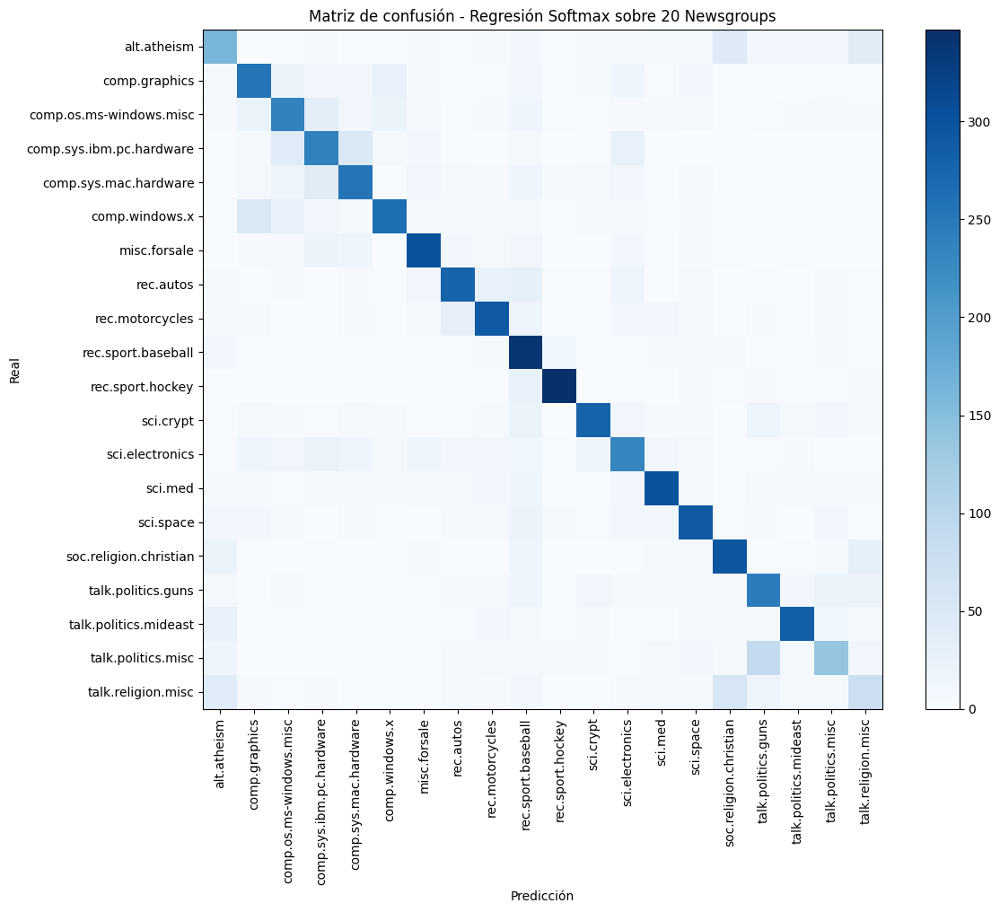

,clase real,predicha como,cantidad
0,talk.politics.misc,talk.politics.guns,89
1,talk.religion.misc,soc.religion.christian,56
2,comp.windows.x,comp.graphics,50
3,comp.sys.ibm.pc.hardware,comp.sys.mac.hardware,48
4,alt.atheism,soc.religion.christian,43
5,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,42
6,talk.religion.misc,alt.atheism,40
7,alt.atheism,talk.religion.misc,39
8,comp.sys.mac.hardware,comp.sys.ibm.pc.hardware,38
9,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,35


In [20]:
def plot_confusion(cm, title):
    """Matriz de confusión como mapa de calor."""
    plt.figure(figsize=(12, 10))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
    plt.yticks(range(NUM_CLASSES), class_names)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def top_confusions(cm, k=10):
    """Los k pares (clase real, clase predicha) con más errores, excluyendo la diagonal."""
    off = cm.copy()
    np.fill_diagonal(off, 0)
    rows = []
    for idx in np.argsort(off, axis=None)[::-1][:k]:
        i, j = np.unravel_index(idx, off.shape)
        rows.append((class_names[i], class_names[j], int(off[i, j])))
    return pd.DataFrame(rows, columns=["clase real", "predicha como", "cantidad"])


r = res_final[SEED]
test_accuracy = accuracy_score(r["labels"], r["preds"])
print(f"Accuracy en test (semilla {SEED}): {test_accuracy:.4f}")

# Intervalo de confianza del 95 % por bootstrap sobre los documentos de test (2.000 remuestreos)
correct = (r["preds"] == r["labels"]).astype(float)
rng = np.random.default_rng(SEED)
boot = correct[rng.integers(0, len(correct), size=(2000, len(correct)))].mean(axis=1)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
print(f"IC 95 % (bootstrap): [{ci_lo:.4f}, {ci_hi:.4f}]\n")

report = classification_report(r["labels"], r["preds"], target_names=class_names, output_dict=True)
print(classification_report(r["labels"], r["preds"], target_names=class_names))

cm_final = confusion_matrix(r["labels"], r["preds"])
plot_confusion(cm_final, "Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
conf_table = top_confusions(cm_final)
display(conf_table)

**Lectura de la matriz de confusión y del reporte por clase (semilla 42).**
- Accuracy en test 0.6780 (IC 95 % por bootstrap: [0.6681, 0.6887]); macro-F1 0.6676 (5 semillas).
- La diagonal domina, y los errores se agrupan en tres bloques temáticos: hardware y sistemas de `comp.*`, religión (`alt.atheism`, `soc.religion.christian`, `talk.religion.misc`) y política (`talk.politics.*`).
- Las confusiones más frecuentes son talk.politics.misc → talk.politics.guns (89 documentos), talk.religion.misc → soc.religion.christian (56), comp.windows.x → comp.graphics (50), comp.sys.ibm.pc.hardware → comp.sys.mac.hardware (48), alt.atheism → soc.religion.christian (43) y comp.sys.ibm.pc.hardware → comp.os.ms-windows.misc (42). Las otras cuatro de las diez primeras son talk.religion.misc ↔ alt.atheism (40 y 39) y comp.sys.mac.hardware ↔ comp.sys.ibm.pc.hardware, comp.os.ms-windows.misc ↔ comp.sys.ibm.pc.hardware (38 y 35).
- Las clases con peor F1 son talk.religion.misc (0.33, recall 0.30, la de menos documentos de test: 251), talk.politics.misc (0.50) y alt.atheism (0.50). Las mejores son rec.sport.hockey (0.89), talk.politics.mideast (0.79) y sci.med (0.78).
- rec.sport.baseball tiene recall 0.86 pero precisión 0.56: la columna de esa clase muestra tonos claros en varias filas, es decir, documentos de otros temas que el modelo asigna a baseball.
- Con TF-IDF cada documento es una bolsa de palabras: las clases con vocabulario compartido se solapan y el modelo no dispone de orden ni contexto para separarlas. Las clases "misc" reúnen temas de varias áreas y se confunden con las específicas.

## 9. Dinámica del entrenamiento

Esta sección usa **solo la partición de entrenamiento/validación** (el test no interviene). Se toma la mejor configuración de la búsqueda y se entrena **30 épocas, sin early stopping ni pruning**, repitiendo cada variante con 3 semillas (`ABL_SEEDS`). Las curvas muestran la media y una banda de ±1 desvío estándar entre semillas.

Primero se observa la dinámica de la configuración óptima (cuándo aparece el sobreajuste) y luego se **varía un solo hiperparámetro por vez**, manteniendo el resto fijo:

1. **Learning rate**: de dos órdenes de magnitud menos a dos más que el óptimo.
2. **Batch size**.
3. **Vectorización**: tamaño del vocabulario (`max_features`) y n-gramas.
4. **Regularización**: `weight_decay`.

Los gráficos muestran `val_acc`, `val_loss` (escala log), `train_loss` (escala log) y el tiempo hasta converger. Las tablas incluyen época y tiempo de convergencia, tiempo por época, *gap* final entre entrenamiento y validación y si hubo divergencia (pérdida no finita).

**Cómo leer los resultados (hipótesis a contrastar):**
- Un `lr` muy bajo da pasos chicos: la pérdida baja lentamente y la curva queda en un *plateau* durante muchas épocas. Un `lr` muy alto acerca rápido al mínimo pero produce curvas ruidosas, un piso en la pérdida o directamente divergencia.
- Con un `batch_size` chico cada época hace más actualizaciones, pero con gradientes más ruidosos y menos aprovechamiento de la GPU. Con uno grande cada época cuesta menos tiempo pero hacen falta más épocas. El balance se mide con el tiempo de convergencia, no con las épocas.
- Un vocabulario mayor (`max_features`) aporta información pero agranda la capa lineal (más parámetros y más tiempo por época). Los bigramas agregan contexto, pero también muchos términos raros.
- `weight_decay` penaliza los pesos grandes: si el problema es de alta varianza, un valor moderado debería reducir el *gap* entre entrenamiento y validación; un valor excesivo produce subajuste.

In [21]:
# Utilidades de los experimentos de un factor por vez
ABL_EPOCHS = 30
ABL_SEEDS = [42, 123, 2024]


def ms(values, d=4):
    """Formatea media ± desvío estándar."""
    return f"{np.mean(values):.{d}f} ± {np.std(values):.{d}f}"


def run_curve(p, seed, epochs, tag):
    """Entrena una configuración durante un número fijo de épocas (sin early stopping) y devuelve su historia."""
    set_seed(seed)
    X_tr, X_val = get_search_features(p)
    train_loader = TensorLoader(X_tr, y_tr, p["batch_size"], shuffle=True)
    val_loader = TensorLoader(X_val, y_val, p["batch_size"], shuffle=False)
    model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES)
    optimizer = build_optimizer(model, p)
    safe_tag = re.sub(r"[^A-Za-z0-9_.=-]", "_", tag)
    writer = SummaryWriter(log_dir=f"runs/dynamics/{safe_tag}_seed{seed}")
    with mlflow.start_run(run_name=f"dynamics_{safe_tag}_seed{seed}"):
        mlflow.log_params({**p, "seed": seed, "n_params": count_params(model)})
        h = train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=writer,
                                run_name=safe_tag, patience=None, verbose=False)
        mlflow.log_metrics({"best_val_acc": h["best_val_acc"], "conv_epoch": h["conv_epoch"],
                            "conv_time_s": h["conv_time"], "train_time_s": h["train_time"]})
    writer.close()
    del train_loader, val_loader, model, optimizer
    free_memory()
    return h


def ablation(name, variants, epochs=ABL_EPOCHS, seeds=ABL_SEEDS):
    """Ejecuta cada variante con todas las semillas. Devuelve {variante: [historia por semilla]}."""
    curves = {}
    for label, p in variants.items():
        curves[label] = [run_curve(p, s, epochs, f"{name}_{label}") for s in seeds]
        print(f"  {name} | {label}: listo")
    return curves


def ablation_table(curves):
    """Tabla resumen (media ± desvío entre semillas) de rendimiento, convergencia, tiempos y gap."""
    rows = []
    for label, hs in curves.items():
        rows.append({
            "variante": label,
            "mejor val_acc": ms([h["best_val_acc"] for h in hs]),
            "época de convergencia": ms([h["conv_epoch"] for h in hs], 1),
            "tiempo hasta converger (s)": ms([h["conv_time"] for h in hs], 2),
            "s/época": ms([np.mean(h["epoch_time"]) for h in hs], 3),
            "gap train-val final": ms([h["final_train_acc"] - h["final_val_acc"] for h in hs]),
            "diverge": any(not np.isfinite(h["train_loss"]).all() for h in hs),
        })
    return pd.DataFrame(rows).set_index("variante")


def plot_ablation(curves, title):
    """val_acc, val_loss y train_loss por época (media ± 1 desvío) y tiempo hasta converger por variante."""
    fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
    for label, hs in curves.items():
        for ax, key in zip(axes[:3], ["val_acc", "val_loss", "train_loss"]):
            arr = np.array([h[key] for h in hs], dtype=float)
            m, s = arr.mean(axis=0), arr.std(axis=0)
            x = np.arange(1, arr.shape[1] + 1)
            ax.plot(x, m, label=label)
            ax.fill_between(x, m - s, m + s, alpha=0.2)
    axes[0].set(title="val_acc", xlabel="época", ylabel="accuracy")
    axes[1].set(title="val_loss", xlabel="época", ylabel="cross-entropy", yscale="log")
    axes[2].set(title="train_loss", xlabel="época", ylabel="cross-entropy", yscale="log")
    axes[0].legend(fontsize=8)
    labels = list(curves.keys())
    means = [np.mean([h["conv_time"] for h in curves[l]]) for l in labels]
    stds = [np.std([h["conv_time"] for h in curves[l]]) for l in labels]
    axes[3].bar(range(len(labels)), means, yerr=stds, capsize=3)
    axes[3].set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
    axes[3].set(title="Tiempo hasta converger", ylabel="segundos")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()



mlflow.end_run()
base = dict(params_best)
print("Configuración base:", base)

Configuración base: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 2, 'lr': 0.014912108612863762, 'weight_decay': 1.9452373422425135e-07, 'batch_size': 256}


### 9.1 Dinámica de la configuración óptima

Se entrena la mejor configuración 30 épocas sin early stopping para observar cuándo la validación deja de mejorar mientras el entrenamiento continúa. La línea vertical punteada marca la época con mayor `val_acc` y la sólida la de menor `val_loss`.

  base | configuración óptima: listo


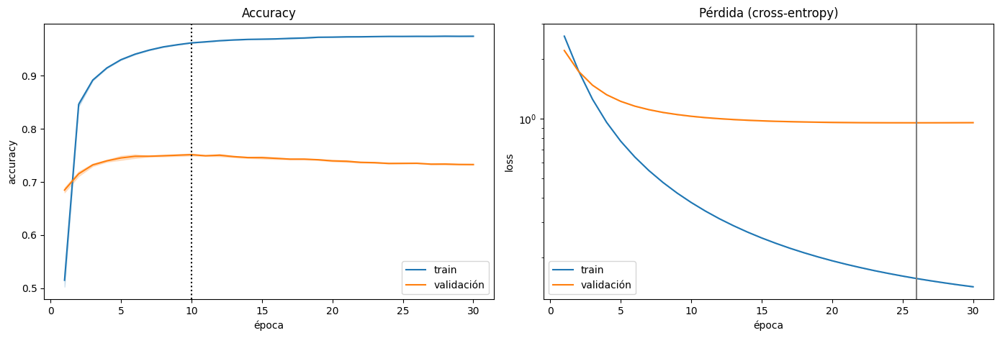

,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
configuración óptima,0.7533 ± 0.0006,6.7 ± 1.7,0.34 ± 0.09,0.050 ± 0.002,0.2414 ± 0.0006,False


In [22]:
# Dinámica de la configuración óptima: curvas de accuracy y pérdida de entrenamiento y validación
curves_base = ablation("base", {"configuración óptima": base})
hs = curves_base["configuración óptima"]
x = np.arange(1, ABL_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for key, label, color in [("train_acc", "train", "tab:blue"), ("val_acc", "validación", "tab:orange")]:
    arr = np.array([h[key] for h in hs])
    axes[0].plot(x, arr.mean(0), label=label, color=color)
    axes[0].fill_between(x, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), alpha=0.2, color=color)
for key, label, color in [("train_loss", "train", "tab:blue"), ("val_loss", "validación", "tab:orange")]:
    arr = np.array([h[key] for h in hs])
    axes[1].plot(x, arr.mean(0), label=label, color=color)
    axes[1].fill_between(x, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), alpha=0.2, color=color)

mean_val_acc = np.array([h["val_acc"] for h in hs]).mean(0)
mean_val_loss = np.array([h["val_loss"] for h in hs]).mean(0)
best_ep_dyn, loss_min_ep_dyn = int(mean_val_acc.argmax()) + 1, int(mean_val_loss.argmin()) + 1
axes[0].axvline(best_ep_dyn, ls=":", color="k")
axes[1].axvline(loss_min_ep_dyn, ls="-", color="gray")
axes[0].set(title="Accuracy", xlabel="época", ylabel="accuracy")
axes[1].set(title="Pérdida (cross-entropy)", xlabel="época", ylabel="loss", yscale="log")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

df_dyn = ablation_table(curves_base)
display(df_dyn)

**Lectura de la dinámica de la configuración óptima (3 semillas, 30 épocas).**
- La `val_acc` media sube rápido (0.685 en la época 1, 0.745 en la 5) y llega a su máximo de 0.7514 en la época 10. Entre las épocas 6 y 12 queda en una meseta (0.748–0.751), con desvío entre semillas de hasta 0.003, y después baja de forma lenta y sostenida hasta 0.7328 en la época 30 (1.9 puntos por debajo del máximo).
- La `train_acc` sube de 0.515 a 0.962 en la época 10 y se estanca en ≈0.974; la `train_loss` sigue bajando hasta 0.143. El gap entre entrenamiento y validación pasa de 0.210 en la época 10 a 0.241 en la 30.
- La `val_loss` es distinta de la accuracy: baja casi sin pausa hasta su mínimo de 0.954 en la época 26 y queda prácticamente plana desde la 15 (0.976 → 0.956). Es decir, la accuracy empeora mientras la pérdida de validación no sube. La accuracy depende solo de qué clase tiene el score máximo; la entropía cruzada depende de las probabilidades asignadas, por lo que puede seguir mejorando mientras algunos documentos cercanos a la frontera cambian de clase.
- Diagnóstico: con error de entrenamiento de ≈2.6 % (0.974) y un gap de 21 a 24 puntos, el modelo es de **alta varianza**, no de falta de capacidad. La época elegida con validación (12 en el entrenamiento final, 0.7503) queda a 0.1 puntos del máximo, dentro del desvío entre semillas, por lo que cualquier época de la meseta es equivalente.
- Para reducir la varianza: más datos, regularización L2 o L1, menos vocabulario y early stopping. En las secciones 9.4 y 9.5 se prueban el vocabulario y la regularización L2.

### 9.2 Learning rate

Se multiplica el `lr` óptimo por 0.01, 0.1, 1, 10 y 100, manteniendo todo lo demás fijo. Se esperan: *plateau* con `lr` bajo, un óptimo intermedio, ruido y piso de pérdida con `lr` alto y, en el extremo, entrenamiento que no se asienta.

  lr | lr x0.01 (1.5e-04): listo
  lr | lr x0.1 (1.5e-03): listo
  lr | lr x1 (1.5e-02): listo
  lr | lr x10 (1.5e-01): listo
  lr | lr x100 (1.5e+00): listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
lr x0.01 (1.5e-04),0.6251 ± 0.0029,29.0 ± 0.0,1.41 ± 0.01,0.049 ± 0.000,0.1683 ± 0.0024,False
lr x0.1 (1.5e-03),0.7359 ± 0.0015,21.3 ± 2.6,1.08 ± 0.11,0.050 ± 0.002,0.1884 ± 0.0015,False
lr x1 (1.5e-02),0.7533 ± 0.0006,6.7 ± 1.7,0.35 ± 0.09,0.051 ± 0.001,0.2414 ± 0.0006,False
lr x10 (1.5e-01),0.7366 ± 0.0044,1.7 ± 0.5,0.08 ± 0.03,0.050 ± 0.001,0.2654 ± 0.0032,False
lr x100 (1.5e+00),0.6621 ± 0.0031,1.7 ± 0.9,0.08 ± 0.05,0.050 ± 0.002,0.2925 ± 0.0057,False


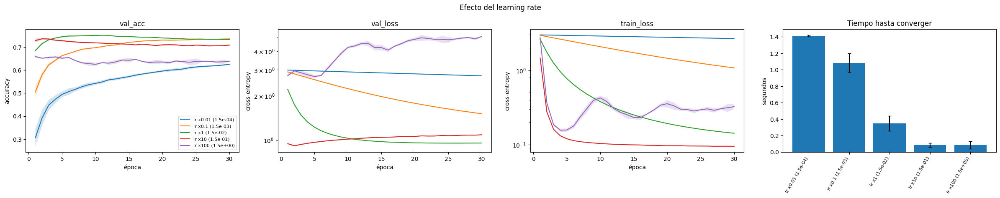

In [23]:
# Efecto del learning rate (un factor por vez)
lr_variants = {f"lr x{m:g} ({base['lr'] * m:.1e})": {**base, "lr": base["lr"] * m} for m in [0.01, 0.1, 1, 10, 100]}
curves_lr = ablation("lr", lr_variants)
df_abl_lr = ablation_table(curves_lr)
df_abl_lr.to_csv(f"{RESULTS_DIR}/ablation_lr.csv")
display(df_abl_lr)
plot_ablation(curves_lr, "Efecto del learning rate")

**Lectura de las curvas de learning rate (3 semillas).**
- Con ×1 (1.5·10⁻²) la `val_acc` máxima es 0.7533 ± 0.0006 en la época 10 y converge en 6.7 épocas (0.35 s).
- Con `lr` bajo el entrenamiento queda en un plateau lento: con ×0.01 la `train_loss` baja de 2.99 a 2.67 en 30 épocas y la `val_acc` llega a 0.625 todavía en ascenso; con ×0.1, la `val_acc` llega a 0.736 en la época 30, también en ascenso. Ninguna de las dos converge dentro del tope de 30 épocas (épocas de convergencia 29.0 y 21.3).
- Con ×10 (0.15) la `val_acc` ya es 0.729 en la época 1 y alcanza su máximo (0.736) en la época 2; después baja hasta 0.709 y la `val_loss` sube de 0.915 a 1.088. Converge en 1.7 épocas (0.08 s, unas 4 veces menos que ×1) pero queda 1.7 puntos por debajo y es más variable entre semillas (desvío 0.0044 contra 0.0006).
- Con ×100 (1.5) el modelo nunca mejora tras la época 1 (`val_acc` 0.659 y luego 0.62–0.65). La `train_loss` cae a 0.157 en la época 4–5, vuelve a subir hasta 0.425 en la época 10 y oscila, y la `val_loss` sube de 2.70 a 5.05: el paso es demasiado grande para asentarse. La pérdida se mantiene finita, así que la columna `diverge` no lo detecta, y su "época de convergencia" (1.7) solo indica que el máximo ocurre al inicio.
- El tiempo por época no depende del `lr` (0.049–0.051 s): el tiempo de convergencia refleja únicamente el número de épocas.
- El gap final crece con el `lr` (0.168, 0.188, 0.241, 0.265, 0.292). Con `lr` bajo es pequeño porque el modelo apenas ajustó el entrenamiento (`train_acc` final 0.79 con ×0.01), no porque generalice mejor.
- Un `lr` bajo da pasos pequeños (plateau); uno alto acerca rápido al mínimo pero deja el entrenamiento ruidoso y sobreajusta antes (peak en la época 2 con ×10 contra la 10 con ×1).
- Limitaciones: con ×0.01 y ×0.1 la época de convergencia está limitada por el tope de 30 épocas; son 3 semillas y un único punto de partida.

### 9.3 Batch size

Se varía `batch_size` entre 32 y 512 con el `lr` fijo. A igual número de épocas, un batch chico hace más actualizaciones por época (más pasos, más ruido) y uno grande hace menos pasos pero más baratos en GPU. El tiempo por época y el tiempo de convergencia muestran el balance. Como el `lr` no se resintoniza para cada tamaño, parte del efecto observado puede deberse a la interacción entre `lr` y batch.

  batch_size | bs=32: listo
  batch_size | bs=64: listo
  batch_size | bs=128: listo
  batch_size | bs=256: listo
  batch_size | bs=512: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
bs=32,0.7477 ± 0.0025,3.0 ± 0.0,1.17 ± 0.01,0.393 ± 0.003,0.2619 ± 0.0011,False
bs=64,0.7493 ± 0.0036,4.7 ± 1.2,0.92 ± 0.25,0.194 ± 0.003,0.2558 ± 0.0016,False
bs=128,0.7497 ± 0.0002,5.0 ± 0.8,0.49 ± 0.07,0.095 ± 0.002,0.2475 ± 0.0010,False
bs=256,0.7533 ± 0.0006,6.7 ± 1.7,0.36 ± 0.11,0.052 ± 0.003,0.2414 ± 0.0006,False
bs=512,0.7518 ± 0.0012,8.3 ± 0.5,0.27 ± 0.02,0.031 ± 0.001,0.2383 ± 0.0010,False


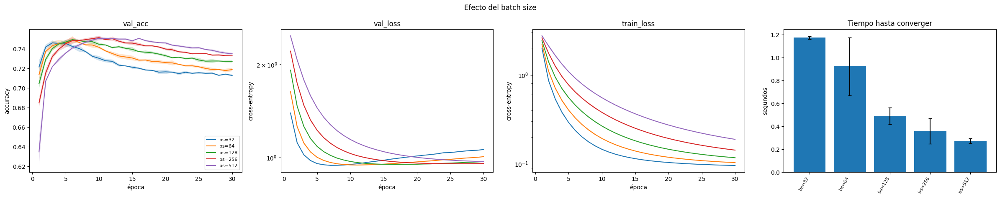

In [24]:
# Efecto del batch size (un factor por vez)
bs_variants = {f"bs={b}": {**base, "batch_size": b} for b in SPACE["batch_size"]}
curves_bs = ablation("batch_size", bs_variants)
df_abl_bs = ablation_table(curves_bs)
df_abl_bs.to_csv(f"{RESULTS_DIR}/ablation_batch_size.csv")
display(df_abl_bs)
plot_ablation(curves_bs, "Efecto del batch size")

**Lectura de las curvas de batch size (3 semillas, `lr` fijo).**
- La mejor `val_acc` es parecida entre tamaños (0.7477, 0.7493, 0.7497, 0.7533, 0.7518 para 32 a 512; rango 0.56 puntos, comparable a los desvíos de hasta 0.0036), por lo que solo cabe afirmar que 32 queda algo por debajo.
- Lo que cambia es la dinámica: el máximo de `val_acc` ocurre en la época 3 con batch 32, en la 6 con 64 y 128 y en la 10 con 256 y 512, y la `val_loss` alcanza su mínimo en la época 7, 11, 17, 26 y 30 respectivamente. Con lotes chicos el sobreajuste empieza antes: la `val_acc` final cae 3.3 puntos por debajo del máximo con 32 y 1.6 con 512.
- El costo: el tiempo por época baja de 0.393 s (32) a 0.031 s (512), unas 13 veces menos, mientras que las épocas hasta converger suben de 3.0 a 8.3. El tiempo hasta converger es mínimo con 512 (0.27 s) y máximo con 32 (1.17 s), 4.3 veces más.
- El gap final disminuye con el batch (0.262 con 32, 0.238 con 512) y la `train_loss` final es menor con lotes chicos (0.096 contra 0.188): el ruido de los lotes chicos no actuó como regularizador.
- Con lotes grandes cada actualización usa un gradiente mejor estimado y mejor aprovecha la GPU; hacen falta más épocas, pero cada una es mucho más barata.
- Limitación: el `lr` no se resintonizó por tamaño de batch, por lo que parte del efecto puede deberse a esa interacción.

### 9.4 Vectorización

Se varía por separado el tamaño del vocabulario (`max_features`) y el uso de bigramas (`ngram_range`), con el resto fijo. Un vocabulario mayor aumenta la dimensión de entrada y, con ella, el número de parámetros de la capa lineal (`20 × max_features + 20`) y el costo por época. Con el vocabulario fijo, los bigramas desplazan unigramas del vocabulario, por lo que esta comparación no separa el efecto del contexto del efecto del tamaño efectivo del vocabulario.

  max_features | max_features=2000: listo
  max_features | max_features=5000: listo
  max_features | max_features=10000: listo
  max_features | max_features=20000: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
max_features=2000,0.6528 ± 0.0004,6.0 ± 0.8,0.30 ± 0.02,0.050 ± 0.004,0.3254 ± 0.0007,False
max_features=5000,0.7167 ± 0.0004,5.3 ± 0.5,0.26 ± 0.03,0.072 ± 0.032,0.2760 ± 0.0017,False
max_features=10000,0.7385 ± 0.0014,6.0 ± 1.4,0.30 ± 0.08,0.050 ± 0.000,0.2584 ± 0.0004,False
max_features=20000,0.7533 ± 0.0006,6.7 ± 1.7,0.36 ± 0.13,0.050 ± 0.002,0.2414 ± 0.0006,False


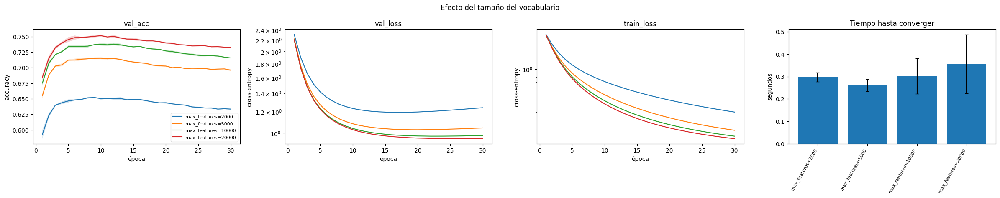

  ngram_range | ngram_range=1gram: listo
  ngram_range | ngram_range=1_2gram: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
ngram_range=1gram,0.7533 ± 0.0006,6.7 ± 1.7,0.36 ± 0.12,0.050 ± 0.002,0.2414 ± 0.0006,False
ngram_range=1_2gram,0.7082 ± 0.0008,6.0 ± 0.8,0.33 ± 0.02,0.052 ± 0.003,0.2825 ± 0.0011,False


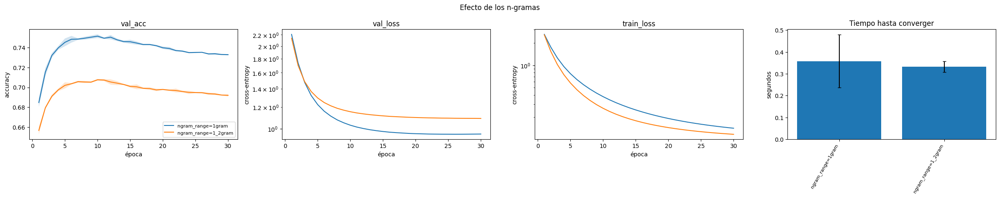

In [25]:
# Efecto del tamaño del vocabulario y de los n-gramas (un factor por vez)
mf_variants = {f"max_features={m}": {**base, "max_features": m} for m in SPACE["max_features"]}
curves_mf = ablation("max_features", mf_variants)
df_abl_mf = ablation_table(curves_mf)
df_abl_mf.to_csv(f"{RESULTS_DIR}/ablation_max_features.csv")
display(df_abl_mf)
plot_ablation(curves_mf, "Efecto del tamaño del vocabulario")

ng_variants = {f"ngram_range={n}": {**base, "ngram_range": n} for n in ["1gram", "1_2gram"]}
curves_ng = ablation("ngram_range", ng_variants)
df_abl_ng = ablation_table(curves_ng)
df_abl_ng.to_csv(f"{RESULTS_DIR}/ablation_ngram_range.csv")
display(df_abl_ng)
plot_ablation(curves_ng, "Efecto de los n-gramas")

**Lectura de las figuras de vocabulario y n-gramas (3 semillas).**
- La mejor `val_acc` crece con el vocabulario y con ganancias decrecientes: 0.6528 (2.000), 0.7167 (5.000), 0.7385 (10.000) y 0.7533 (20.000), es decir +6.4, +2.2 y +1.5 puntos. El orden se mantiene en todas las épocas.
- Con pocas características el modelo sigue ajustando el entrenamiento (`train_acc` final 0.959 con 2.000, 0.974 con 20.000) pero generaliza peor: el gap final baja de 0.325 a 0.241 al ampliar el vocabulario. Más vocabulario no aumentó el sobreajuste, sino que aportó información útil. La `val_loss` mínima mejora de 1.193 a 0.954.
- El costo casi no cambia (0.26–0.36 s hasta converger, con barras de error solapadas), a pesar de pasar de 40.020 a 400.020 parámetros. 20.000 es el máximo probado, por lo que no se sabe si más vocabulario seguiría mejorando.
- Los unigramas (0.7533) superan a unigramas + bigramas (0.7082) en 4.5 puntos, en todas las épocas. Con el mismo `max_features`, los bigramas alcanzan la misma `train_acc` (0.9745) pero tienen una `val_loss` mayor (1.090 contra 0.956) y un gap mayor (0.283 contra 0.241); los tiempos son equivalentes. Con el vocabulario fijo, los bigramas desplazan unigramas frecuentes y suman términos raros, que favorecen el sobreajuste.
- Limitación: esta comparación no separa el efecto del contexto que aportan los bigramas del efecto de reducir los unigramas disponibles.

### 9.5 Regularización: `weight_decay`

El *gap* entre entrenamiento y validación indica varianza alta. `weight_decay` agrega una penalización L2 sobre los pesos: con un valor moderado debería reducir ese gap y la `val_loss` final; con un valor excesivo el modelo no logra ajustar siquiera el entrenamiento (sesgo alto). Se incluye `weight_decay=0` como referencia sin regularizar.

  weight_decay | wd=0: listo
  weight_decay | wd=2e-07: listo
  weight_decay | wd=1e-06: listo
  weight_decay | wd=1e-05: listo
  weight_decay | wd=1e-04: listo
  weight_decay | wd=1e-03: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
wd=0,0.7524 ± 0.0004,6.0 ± 0.8,0.59 ± 0.47,0.067 ± 0.028,0.2405 ± 0.0004,False
wd=2e-07,0.7533 ± 0.0006,6.7 ± 1.7,0.33 ± 0.09,0.050 ± 0.002,0.2414 ± 0.0006,False
wd=1e-06,0.7517 ± 0.0010,6.7 ± 0.5,0.35 ± 0.02,0.051 ± 0.001,0.2432 ± 0.0012,False
wd=1e-05,0.7439 ± 0.0011,6.0 ± 0.8,0.30 ± 0.04,0.050 ± 0.002,0.2458 ± 0.0010,False
wd=1e-04,0.7222 ± 0.0009,11.0 ± 0.8,0.55 ± 0.07,0.049 ± 0.002,0.1604 ± 0.0029,False
wd=1e-03,0.6430 ± 0.0012,3.7 ± 1.2,0.18 ± 0.06,0.051 ± 0.003,0.0316 ± 0.0089,False


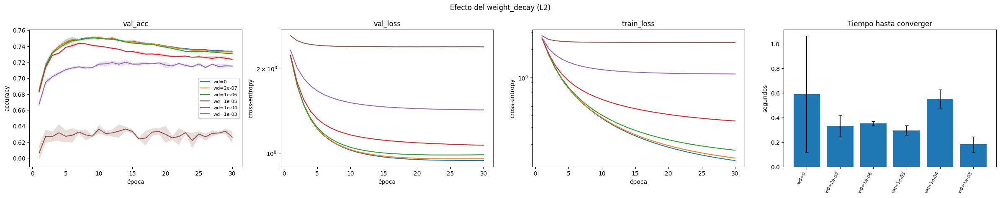

In [26]:
# Efecto del weight_decay (regularización L2), incluyendo la referencia sin regularizar
wd_values = sorted(set([0.0, 1e-6, 1e-5, 1e-4, 1e-3, base["weight_decay"]]))
wd_variants = {f"wd={w:.0e}" if w > 0 else "wd=0": {**base, "weight_decay": w} for w in wd_values}
curves_wd = ablation("weight_decay", wd_variants)
df_abl_wd = ablation_table(curves_wd)
df_abl_wd.to_csv(f"{RESULTS_DIR}/ablation_weight_decay.csv")
display(df_abl_wd)
plot_ablation(curves_wd, "Efecto del weight_decay (L2)")

**Lectura del efecto de `weight_decay` (3 semillas).**
- Hasta 10⁻⁶ las curvas son casi idénticas: mejor `val_acc` 0.7524 (sin regularizar), 0.7533 y 0.7517, y gap final 0.240–0.243. Con 10⁻⁵ la `val_acc` baja a 0.7439 y la `train_loss` final sube de 0.14 a 0.35.
- Con valores mayores el gap cae (0.160 con 10⁻⁴, 0.032 con 10⁻³), pero la `val_acc` también (0.7222 y 0.6430) y la `val_loss` mínima empeora (1.42 y 2.38). La `train_acc` final es de 0.876 y 0.658: la penalización impide ajustar el entrenamiento, es decir, intercambia varianza por sesgo hasta llegar a un subajuste claro con 10⁻³.
- Con 10⁻⁴ la `val_acc` deja de decaer después de su máximo (0.7200 en la época 14, 0.7151 en la 30; una caída de 0.5 puntos contra 1.7 sin regularizar), pero en un nivel más bajo.
- Conclusión: para este modelo, la regularización L2 no mejora la validación respecto de parar en la mejor época. Limitación: la `val_acc` reportada es el máximo sobre épocas (incluye la parada temprana) y el gap se mide en la época 30, por lo que la comparación entre ambas medidas es parcial.

## 10. Análisis de la búsqueda de hiperparámetros

Esta sección analiza **todos los trials**, no solo el mejor:

1. **Pruning**: cuántos trials se podaron y cuánto tiempo se ahorró.
2. **Tabla de trials**: los mejores trials con sus hiperparámetros y tiempos.
3. **Efecto por grupo**: rendimiento y convergencia según cada hiperparámetro.
4. **Learning rate y weight decay**: rendimiento según su valor (incluye trials podados, con la mejor `val_acc` que alcanzaron antes del corte, para no sesgar la comparación hacia los que sobreviven).
5. **Historia de la búsqueda y costo**: si seguía mejorando al final y qué relación hay entre rendimiento y tiempo.
6. **Chequeo de bordes** del espacio de búsqueda.
7. **Importancia de hiperparámetros** (fANOVA).

Los tiempos provienen de `time.perf_counter()` por época. Los promedios por grupo mezclan efectos, porque TPE concentra el muestreo donde ya hubo buenos resultados; los experimentos controlados de la sección 9 aíslan cada factor.

In [27]:
def trials_df(study):
    """DataFrame con todos los trials de un estudio, sus hiperparámetros, atributos y tiempos."""
    d = study.trials_dataframe(attrs=("number", "value", "state", "duration", "params", "user_attrs"))
    d["duration_s"] = d["duration"].dt.total_seconds()
    d["s_per_epoch"] = d["user_attrs_train_time"] / d["user_attrs_epochs_run"]
    d["perf"] = d["user_attrs_best_val_acc"]   # mejor val_acc alcanzada (también para trials podados)
    return d


def pruning_report(df):
    """Trials completos/podados y tiempo ahorrado por la poda (estimado contra el tiempo de un trial completo)."""
    done_, prun_ = df[df["state"] == "COMPLETE"], df[df["state"] == "PRUNED"]
    real = float(prun_["user_attrs_train_time"].sum())
    est = float((prun_["user_attrs_train_time"] / prun_["user_attrs_epochs_run"] * done_["user_attrs_epochs_run"].mean()).sum())
    return pd.DataFrame([{"trials": len(df), "completos": len(done_), "podados": len(prun_),
                          "tiempo real de podados (s)": real, "tiempo estimado sin poda (s)": est,
                          "ahorro (s)": est - real, "ahorro (%)": 100 * (est - real) / est if est else np.nan}]).round(1)


df_trials = trials_df(study)
df_trials.to_csv(f"{RESULTS_DIR}/trials_softmax.csv", index=False)
done = df_trials[df_trials["state"] == "COMPLETE"].copy()
prun = df_trials[df_trials["state"] == "PRUNED"].copy()

print(f"Trials: {len(df_trials)} | completos: {len(done)} | podados: {len(prun)}")
print("Pruning (el tiempo sin poda se estima como tiempo por época del trial podado x épocas medias de un trial completo):")
pruning_tbl = pruning_report(df_trials)
display(pruning_tbl)

print("\nTop 10 trials:")
cols = ["number", "value", "user_attrs_best_epoch", "user_attrs_conv_epoch", "user_attrs_conv_time",
        "user_attrs_train_time", "s_per_epoch", "params_lr", "params_weight_decay", "params_batch_size",
        "params_max_features", "params_min_df", "params_ngram_range", "params_normalization", "params_remove_stopwords"]
top10 = done.sort_values("value", ascending=False)[cols].head(10).round(5)
top10.to_csv(f"{RESULTS_DIR}/top10_trials.csv", index=False)
display(top10)

Trials: 200 | completos: 129 | podados: 71
Pruning (el tiempo sin poda se estima como tiempo por época del trial podado x épocas medias de un trial completo):


,trials,completos,podados,tiempo real de podados (s),tiempo estimado sin poda (s),ahorro (s),ahorro (%)
0,200,129,71,21.0,58.7,37.8,64.3



Top 10 trials:


,number,value,user_attrs_best_epoch,user_attrs_conv_epoch,user_attrs_conv_time,user_attrs_train_time,s_per_epoch,params_lr,params_weight_decay,params_batch_size,params_max_features,params_min_df,params_ngram_range,params_normalization,params_remove_stopwords
138,138,0.75342,9,7,0.38754,0.76083,0.05434,0.01694,0.0,256,20000,2,1gram,stem,False
98,98,0.75342,12,9,0.45892,0.85736,0.05043,0.01491,0.0,256,20000,2,1gram,stem,False
142,142,0.75342,6,5,0.99767,2.23502,0.20318,0.01407,0.0,64,20000,2,1gram,stem,False
165,165,0.75298,6,5,0.98290,2.30692,0.20972,0.01330,0.0,64,20000,2,1gram,stem,False
88,88,0.75298,6,4,0.19194,0.54296,0.04936,0.02807,0.0,256,20000,2,1gram,stem,False
167,167,0.75298,9,5,0.26919,0.74951,0.05354,0.02018,0.0,256,20000,2,1gram,stem,False
90,90,0.75298,12,9,0.50348,0.95272,0.05604,0.01510,0.0,256,20000,2,1gram,stem,False
179,179,0.75254,6,5,0.49508,1.08096,0.09827,0.02251,0.0,128,20000,2,1gram,stem,False
69,69,0.75254,9,5,0.29155,0.76357,0.05454,0.02085,0.0,256,20000,2,1gram,stem,False
91,91,0.75254,9,5,0.25263,0.70495,0.05035,0.01881,0.0,256,20000,1,1gram,stem,False


In [28]:
# Resumen por valor de cada hiperparámetro (trials completos): rendimiento, convergencia, tiempo y tamaño
def summary_by(df, col, value_col="value"):
    return df.groupby(col, observed=True).agg(
        n=(value_col, "count"), val_acc_media=(value_col, "mean"), val_acc_std=(value_col, "std"),
        val_acc_max=(value_col, "max"), epoca_conv_media=("user_attrs_conv_epoch", "mean"),
        tiempo_conv_medio_s=("user_attrs_conv_time", "mean"), s_por_epoca=("s_per_epoch", "mean"),
        params_medios=("user_attrs_n_params", "mean")).round(4)


group_cols = ["params_batch_size", "params_max_features", "params_min_df", "params_ngram_range",
              "params_normalization", "params_remove_stopwords"]
group_tables = {}
for col in group_cols:
    group_tables[col] = summary_by(done, col)
    print(f"--- por {col.replace('params_', '')} (trials completos) ---")
    display(group_tables[col])
pd.concat(group_tables, names=["hiperparámetro", "valor"]).to_csv(f"{RESULTS_DIR}/summary_by_hyperparameter.csv")

# lr y weight_decay (continuos): cuartiles sobre todos los trials con rendimiento registrado
perf_df = df_trials[df_trials["perf"].notna()].copy()
cont_tables = {}
for col in ["params_lr", "params_weight_decay"]:
    perf_df[f"{col}_cuartil"] = pd.qcut(perf_df[col], 4, duplicates="drop")
    cont_tables[col] = summary_by(perf_df, f"{col}_cuartil", value_col="perf")
    print(f"--- por cuartil de {col.replace('params_', '')} (todos los trials, incluidos podados) ---")
    display(cont_tables[col])
pd.concat(cont_tables, names=["hiperparámetro", "cuartil"]).to_csv(f"{RESULTS_DIR}/summary_by_continuous.csv")

--- por batch_size (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_batch_size,,,,,,,,
32,9,0.7224,0.0419,0.7455,3.5556,1.4538,0.4063,218535.5556
64,18,0.7387,0.0290,0.7534,4.2222,1.0544,0.2148,349750.0000
128,29,0.7276,0.0457,0.7525,4.5172,0.4499,0.1004,275776.5517
256,62,0.7463,0.0173,0.7534,5.0645,0.2669,0.0529,367713.5484
512,11,0.7000,0.0681,0.7494,8.7273,0.3262,0.0345,256692.7273


--- por max_features (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_max_features,,,,,,,,
2000,4,0.6008,0.0383,0.6346,12.0000,1.4784,0.1390,40020.0000
5000,7,0.6929,0.0401,0.7238,6.8571,0.6950,0.1512,100020.0000
10000,22,0.7311,0.0092,0.7406,4.7273,0.5455,0.1450,197532.7273
20000,96,0.7451,0.0263,0.7534,4.6771,0.4424,0.0968,382039.1667


--- por min_df (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_min_df,,,,,,,,
1,16,0.7306,0.0548,0.7525,5.0625,0.2877,0.0655,346270.0000
2,95,0.7426,0.0276,0.7534,4.5579,0.4325,0.1093,352797.2632
5,18,0.7015,0.0442,0.7384,7.5000,1.0866,0.1479,156980.0000


... (6 outputs left out)

--- por cuartil de lr (todos los trials, incluidos podados) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_lr_cuartil,,,,,,,,
"(-0.0008810000000000001, 0.0114]",50,0.7116,0.0433,0.7521,6.70,0.7651,0.1165,292112.4
"(0.0114, 0.0172]",50,0.7298,0.0332,0.7534,4.56,0.3835,0.0945,303610.4
"(0.0172, 0.0267]",50,0.7410,0.0222,0.7530,4.02,0.3145,0.0920,336195.6
"(0.0267, 0.0974]",50,0.7317,0.0362,0.7530,2.56,0.1767,0.0801,315257.2


--- por cuartil de weight_decay (todos los trials, incluidos podados) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_weight_decay_cuartil,,,,,,,,
"(-0.00099999, 2.66e-08]",50,0.7366,0.0240,0.7530,3.98,0.3059,0.0839,318858.8
"(2.66e-08, 9.51e-08]",50,0.7305,0.0314,0.7530,3.92,0.2981,0.0873,314583.6
"(9.51e-08, 4.27e-07]",50,0.7290,0.0373,0.7534,4.48,0.3753,0.1013,333026.4
"(4.27e-07, 0.00184]",50,0.7180,0.0460,0.7530,5.46,0.6604,0.1106,280706.8


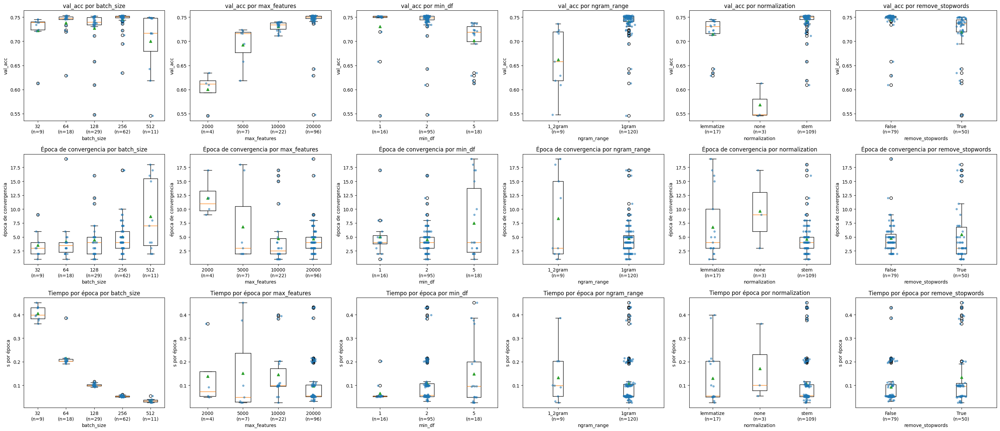

In [29]:
# Distribución de val_acc y de la época de convergencia por hiperparámetro categórico
def group_boxplot(ax, df, col, title, xlabel, value_col="value", ylabel="val_acc"):
    cats = sorted(df[col].dropna().unique())
    data = [df.loc[df[col] == c, value_col].dropna().values for c in cats]
    ax.boxplot(data, showmeans=True)
    rng = np.random.default_rng(SEED)
    for i, d in enumerate(data, start=1):
        ax.scatter(rng.normal(i, 0.04, len(d)), d, alpha=0.5, s=14, color="tab:blue", zorder=3)
    ax.set_xticks(range(1, len(cats) + 1))
    ax.set_xticklabels([f"{c}\n(n={len(d)})" for c, d in zip(cats, data)])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)


panels = [("params_batch_size", "batch_size"), ("params_max_features", "max_features"), ("params_min_df", "min_df"),
          ("params_ngram_range", "ngram_range"), ("params_normalization", "normalization"),
          ("params_remove_stopwords", "remove_stopwords")]
fig, axes = plt.subplots(3, 6, figsize=(30, 13))
for j, (col, label) in enumerate(panels):
    group_boxplot(axes[0, j], done, col, f"val_acc por {label}", label)
    group_boxplot(axes[1, j], done, col, f"Época de convergencia por {label}", label,
                  value_col="user_attrs_conv_epoch", ylabel="época de convergencia")
    group_boxplot(axes[2, j], done, col, f"Tiempo por época por {label}", label,
                  value_col="s_per_epoch", ylabel="s por época")
plt.tight_layout()
plt.show()

**Lectura de los boxplots por hiperparámetro.**
- La mayoría de las medianas de `val_acc` están cerca de 0.75, con una cola de trials malos (0.55–0.65). Las categorías con peor rendimiento son `max_features` = 2.000 (todos ≤ 0.635, n = 4), `normalization` = none (0.55–0.61, n = 3) y los bigramas (mediana ≈0.66, n = 9); `batch_size` = 512 tiene la caja más ancha (n = 11).
- La época de convergencia mediana ronda 3–5 en casi todas las categorías, y sube con `batch_size` (mediana ≈7 con 512) y con vocabularios chicos (≈11 con 2.000).
- El tiempo por época queda determinado por el `batch_size` (bandas de ≈0.40, 0.21, 0.10, 0.05 y 0.035 s para 32 a 512); en los demás paneles la dispersión de tiempos refleja la mezcla de tamaños de batch y no el hiperparámetro que se grafica (en 9.4 el vocabulario no cambió el costo por época).
- Los promedios por grupo están confundidos por el muestreo de TPE (96 de 129 trials completos con `max_features` = 20.000, 120 con unigramas, 109 con stemming). Por ejemplo, `batch_size` = 512 es el peor en la búsqueda pero rinde 0.7518 en el experimento controlado.

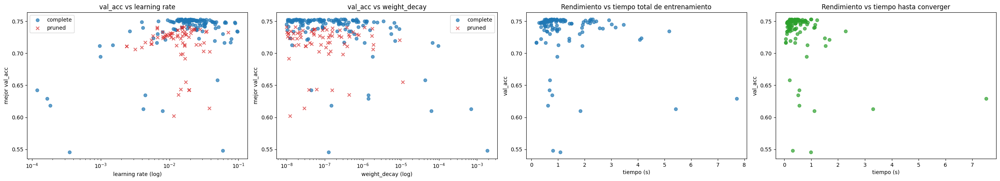

In [30]:
# val_acc contra learning rate y contra weight_decay (completos vs. podados) y rendimiento contra costo
fig, axes = plt.subplots(1, 4, figsize=(26, 4.8))
for ax, (col, label) in zip(axes[:2], [("params_lr", "learning rate"), ("params_weight_decay", "weight_decay")]):
    for state, marker, color in [("COMPLETE", "o", "tab:blue"), ("PRUNED", "x", "tab:red")]:
        s = perf_df[perf_df["state"] == state]
        ax.scatter(s[col], s["perf"], marker=marker, color=color, alpha=0.7, label=state.lower())
    ax.set_xscale("log")
    ax.set(title=f"val_acc vs {label}", xlabel=f"{label} (log)", ylabel="mejor val_acc")
    ax.legend()
axes[2].scatter(done["user_attrs_train_time"], done["value"], alpha=0.7)
axes[2].set(title="Rendimiento vs tiempo total de entrenamiento", xlabel="tiempo (s)", ylabel="val_acc")
axes[3].scatter(done["user_attrs_conv_time"], done["value"], alpha=0.7, color="tab:green")
axes[3].set(title="Rendimiento vs tiempo hasta converger", xlabel="tiempo (s)", ylabel="val_acc")
plt.tight_layout()
plt.show()

**Lectura de `val_acc` contra `lr` y `weight_decay`, y rendimiento contra costo.**
- Los trials completos con `lr` entre 10⁻² y 10⁻¹ forman una meseta de 0.73–0.753; por debajo de 10⁻³ casi no hay trials completos y ninguno supera 0.72. Los trials podados se concentran entre 2·10⁻³ y 4·10⁻² con 0.69–0.74.
- Con `weight_decay` hasta ≈10⁻⁶ los trials completos llegan a ≈0.75; por encima de 10⁻⁵ bajan a 0.71–0.72, y los de 10⁻⁴ o más no superan 0.72.
- Más tiempo de entrenamiento no implica mejor rendimiento: la mayoría de los trials con `val_acc` ≈ 0.75 duran menos de 1.5 s y convergen en 0.2–0.6 s, mientras que los de 4–8 s (batch 32–64) llegan a 0.62–0.745.

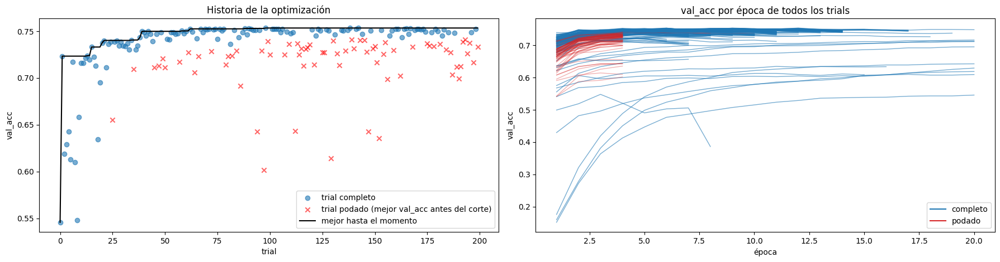

In [31]:
# Historia de la optimización y curvas de val_acc por época de todos los trials (con la acción del pruner)
g_all = df_trials.sort_values("number")
g_done = g_all[g_all["state"] == "COMPLETE"]
g_prun = g_all[g_all["state"] == "PRUNED"]
best_so_far = g_all["value"].fillna(0).cummax()

fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
axes[0].scatter(g_done["number"], g_done["value"], alpha=0.6, label="trial completo")
axes[0].scatter(g_prun["number"], g_prun["perf"], marker="x", color="red", alpha=0.6, label="trial podado (mejor val_acc antes del corte)")
axes[0].plot(g_all["number"], best_so_far, color="k", label="mejor hasta el momento")
axes[0].set(title="Historia de la optimización", xlabel="trial", ylabel="val_acc")
axes[0].legend()

for t in study.trials:
    if not t.intermediate_values:
        continue
    steps, vals = zip(*sorted(t.intermediate_values.items()))
    pruned_t = t.state.name == "PRUNED"
    axes[1].plot([s + 1 for s in steps], vals, color="tab:red" if pruned_t else "tab:blue",
                 alpha=0.35 if pruned_t else 0.6, lw=1)
axes[1].plot([], [], color="tab:blue", label="completo")
axes[1].plot([], [], color="tab:red", label="podado")
axes[1].set(title="val_acc por época de todos los trials", xlabel="época", ylabel="val_acc")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lectura de la historia de la búsqueda y de las curvas por época.**
- La mejor `val_acc` pasa de 0.7402 (25 trials) a 0.7499 (50) y a 0.7534 (100), y después no mejora. Desde el trial ≈50 los trials completos se concentran en 0.745–0.753, y los podados aparecen a lo largo de toda la búsqueda con 0.69–0.74.
- En las curvas por época, la mayoría de los trials completos sube a 0.73–0.75 en 2–4 épocas y queda en meseta. Los podados terminan todos en la época 4 (el primer corte posible con `n_warmup_steps=3`). Un grupo de trials completos sube muy lento y alcanza solo 0.55–0.72 al final de las 20 épocas, todavía en ascenso; son probablemente los de `lr` bajo, y su `val_acc` está subestimada por el tope de épocas.
- Se podaron 71 de 200 trials (35.5 %), con un ahorro estimado de 37.8 s (64 % del tiempo de los podados, ≈6 % de los 626 s de la búsqueda).

,mín. observado,máx. observado,cerca del límite inferior,cerca del límite superior,de
hiperparámetro,,,,,
lr,1.329535e-02,2.807251e-02,0,0,10
weight_decay,1.790655e-08,6.837380e-07,3,0,10
batch_size,6.400000e+01,2.560000e+02,0,0,10
max_features,2.000000e+04,2.000000e+04,0,10,10


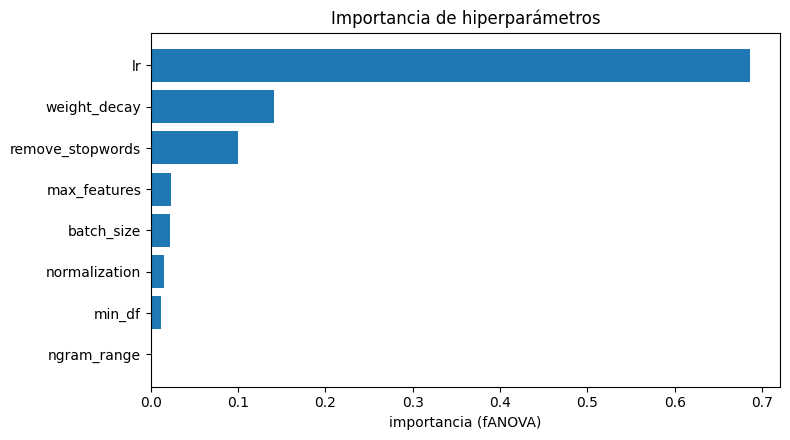

In [32]:
# Chequeo de bordes: cuántos de los 10 mejores trials caen en el 10 % exterior del rango (o en el valor extremo)
def border_report(df, top_k=10, margin=0.1):
    sub = df[df["state"] == "COMPLETE"].nlargest(top_k, "value")
    rows = []
    for name, (low, high) in FLOAT_BOUNDS.items():
        v = sub[f"params_{name}"].to_numpy(dtype=float)
        z = (np.log(v) - np.log(low)) / (np.log(high) - np.log(low))
        rows.append({"hiperparámetro": name, "mín. observado": v.min(), "máx. observado": v.max(),
                     "cerca del límite inferior": int((z <= margin).sum()),
                     "cerca del límite superior": int((z >= 1 - margin).sum()), "de": len(v)})
    for name in ["batch_size", "max_features"]:
        v = sub[f"params_{name}"].to_numpy()
        rows.append({"hiperparámetro": name, "mín. observado": v.min(), "máx. observado": v.max(),
                     "cerca del límite inferior": int((v == min(SPACE[name])).sum()),
                     "cerca del límite superior": int((v == max(SPACE[name])).sum()), "de": len(v)})
    return pd.DataFrame(rows).set_index("hiperparámetro")


border_tbl = border_report(df_trials)
border_tbl.to_csv(f"{RESULTS_DIR}/border_check.csv")
display(border_tbl)

# Importancia de hiperparámetros (fANOVA): correlacional, calculada sobre los trials completos
importance = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
importance.to_csv(f"{RESULTS_DIR}/param_importance.csv")
plt.figure(figsize=(8, 4.5))
plt.barh(importance.index, importance.values)
plt.xlabel("importancia (fANOVA)")
plt.title("Importancia de hiperparámetros")
plt.tight_layout()
plt.show()

**Lectura de la importancia de hiperparámetros (fANOVA).**
- `lr` explica la mayor parte de la variación (0.69), seguido por `weight_decay` (0.14) y `remove_stopwords` (0.10); `max_features`, `batch_size`, `normalization`, `min_df` y `ngram_range` quedan por debajo de 0.025.
- La importancia no equivale al efecto real: `ngram_range` (0.002) y `max_features` (0.023) tuvieron efectos de 4.5 y 10 puntos en los experimentos controlados. La búsqueda los exploró poco (14 trials con bigramas, 11 con ≤ 5.000 características), por lo que fANOVA tiene pocos datos para atribuirles varianza. Es una medida correlacional que depende de la región muestreada.

In [33]:
# Datos de apoyo para el análisis de la búsqued
n_val = len(y_val)
p_hat = study.best_value
se = np.sqrt(p_hat * (1 - p_hat) / n_val)   # error estándar de la accuracy sobre la validación
top = done.nlargest(10, "value")

print(f"Documentos de validación: {n_val} | error estándar de val_acc ≈ {100 * se:.2f} puntos")
print(f"Rango de val_acc de los 10 mejores trials: {top['value'].min():.4f} a {top['value'].max():.4f}")
print(f"Mejor trial: n.º {int(done.loc[done['value'].idxmax(), 'number'])} de {len(df_trials)}")
print("\nImportancia de hiperparámetros (fANOVA):")
display(importance.sort_values(ascending=False).round(3).to_frame("importancia"))

# Dinámica de la configuración óptima (sección 9.1)
print(f"\nÉpoca con mayor val_acc: {best_ep_dyn} | época con menor val_loss: {loss_min_ep_dyn}")
print(f"train_acc final: {np.mean([h['train_acc'][-1] for h in hs]):.4f} | "
      f"val_acc final: {np.mean([h['val_acc'][-1] for h in hs]):.4f}")

Documentos de validación: 2263 | error estándar de val_acc ≈ 0.91 puntos
Rango de val_acc de los 10 mejores trials: 0.7525 a 0.7534
Mejor trial: n.º 98 de 200

Importancia de hiperparámetros (fANOVA):


,importancia
lr,0.686
weight_decay,0.141
remove_stopwords,0.100
max_features,0.023
batch_size,0.022
normalization,0.015
min_df,0.011
ngram_range,0.002



Época con mayor val_acc: 10 | época con menor val_loss: 26
train_acc final: 0.9742 | val_acc final: 0.7328


## 11. Robustez frente a las semillas

Un único entrenamiento o una única búsqueda pueden favorecer una configuración por azar. Se repiten dos cosas:

1. **Entrenamiento final con 5 semillas** (`SEEDS`), con los hiperparámetros y la cantidad de épocas ya elegidos. La semilla afecta la inicialización de los pesos y el orden de los batches; la partición y el vocabulario son fijos. Se reporta media ± desvío.
2. **Búsqueda con otras dos semillas del sampler** (`SEARCH_SEEDS_EXTRA`) y 50 trials cada una, para ver si el resultado y los hiperparámetros elegidos dependen de la semilla. Para comparar con presupuesto equivalente, de la búsqueda principal se considera también el mejor resultado de sus primeros 50 trials. Si la sesión se interrumpe, los estudios se reanudan desde `results/`.

In [34]:
# Entrenamiento final repetido con las 5 semillas (test evaluado una vez por corrida)
mlflow.end_run()
for seed in SEEDS:
    if seed not in res_final:
        res_final[seed] = run_final(params_best, EPOCHS_FINAL, seed=seed, verbose=False)
    print(f"semilla {seed}: listo")

rows = []
for seed, r in res_final.items():
    h = r["history"]
    acc = accuracy_score(r["labels"], r["preds"])
    rows.append({"semilla": seed, "test_acc": acc, "test_macro_F1": f1_score(r["labels"], r["preds"], average="macro"),
                 "train_acc (modelo final)": h["train_acc_eval"], "gap train − test": h["train_acc_eval"] - acc,
                 "tiempo entrenamiento (s)": h["train_time"], "s/época": float(np.mean(h["epoch_time"]))})
df_seeds = pd.DataFrame(rows).sort_values("semilla").reset_index(drop=True)
df_seeds.to_csv(f"{RESULTS_DIR}/final_by_seed.csv", index=False)
display(df_seeds.round(4))

agg = df_seeds.drop(columns="semilla").agg(["mean", "std"]).round(4)
agg.to_csv(f"{RESULTS_DIR}/final_mean_std.csv")
display(agg)

semilla 42: listo
semilla 123: listo
semilla 2024: listo
semilla 7: listo
semilla 99: listo


,semilla,test_acc,test_macro_F1,train_acc (modelo final),gap train − test,tiempo entrenamiento (s),s/época
0,7,0.6768,0.6655,0.9661,0.2893,0.6405,0.0534
1,42,0.6780,0.6670,0.9663,0.2883,0.7259,0.0605
2,99,0.6780,0.6663,0.9664,0.2884,0.6512,0.0543
3,123,0.6798,0.6698,0.9663,0.2866,0.7207,0.0601
4,2024,0.6798,0.6694,0.9663,0.2866,0.6392,0.0533


,test_acc,test_macro_F1,train_acc (modelo final),gap train − test,tiempo entrenamiento (s),s/época
mean,0.6785,0.6676,0.9663,0.2878,0.6755,0.0563
std,0.0013,0.0019,0.0001,0.0012,0.0439,0.0037


In [35]:
# Robustez de la búsqueda frente a la semilla del sampler de Optuna
SEARCH_SEEDS_EXTRA = [123, 2024]
N_TRIALS_REPEAT = 50

repeat_studies = {SEED: study}
for s in SEARCH_SEEDS_EXTRA:
    mlflow.end_run()
    repeat_studies[s] = run_search(f"softmax_search_s{s}", N_TRIALS_REPEAT, seed=s)


def best_first_n(st, n):
    """Mejor val_acc entre los primeros n trials completos de un estudio."""
    return max(t.value for t in st.trials if t.state.name == "COMPLETE" and t.number < n)


rows = []
for s, st in repeat_studies.items():
    p_s = st.best_params
    rows.append({"semilla del sampler": s, "trials": len(st.trials), "mejor val_acc": st.best_value,
                 f"mejor val_acc (primeros {N_TRIALS_REPEAT} trials)": best_first_n(st, N_TRIALS_REPEAT),
                 "lr": p_s["lr"], "weight_decay": p_s["weight_decay"], "batch_size": p_s["batch_size"],
                 "max_features": p_s["max_features"], "ngram_range": p_s["ngram_range"], "min_df": p_s["min_df"],
                 "normalization": p_s["normalization"], "remove_stopwords": p_s["remove_stopwords"]})
df_repeat = pd.DataFrame(rows).set_index("semilla del sampler")
df_repeat.to_csv(f"{RESULTS_DIR}/search_seed_robustness.csv")
display(df_repeat)

,trials,mejor val_acc,mejor val_acc (primeros 50 trials),lr,weight_decay,batch_size,max_features,ngram_range,min_df,normalization,remove_stopwords
semilla del sampler,,,,,,,,,,,
42,200,0.753425,0.749890,0.014912,1.945237e-07,256,20000,1gram,2,stem,False
123,50,0.751215,0.751215,0.011714,9.916307e-07,256,20000,1gram,1,stem,True
2024,50,0.754750,0.754750,0.008896,1.038016e-05,128,20000,1gram,2,stem,True


## 12. Preguntas de reflexión

**Sobre Regresión Softmax (teoría)**

**1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?**

La regresión logística binaria modela la probabilidad de una clase con una sigmoide aplicada a un único score lineal, `p = σ(w·x + b)`. La regresión softmax asigna un score lineal a cada una de las K clases y los convierte en probabilidades que suman 1, con `p_k = exp(z_k) / Σ_j exp(z_j)`. Con K = 2, `p_1 = exp(z_1) / (exp(z_1) + exp(z_2)) = σ(z_1 − z_2)`: es una regresión logística binaria cuyo vector de pesos es la diferencia `w_1 − w_2`. Los dos modelos representan la misma familia de funciones; la softmax con dos clases solo usa el doble de parámetros (`2d + 2` contra `d + 1`) y esa parametrización es redundante, porque sumar el mismo vector a ambas filas no cambia las probabilidades. En este trabajo, con K = 20 y un mejor trial de 376.700 parámetros, cada clase tiene su propio vector de pesos sobre el vocabulario.

**2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?**

`CrossEntropyLoss` de PyTorch calcula internamente `log_softmax` seguido de `NLLLoss`, de forma numéricamente estable (usa el truco de restar el máximo antes de exponenciar). Por eso el `forward` de `SoftmaxRegression` devuelve logits crudos. Si además se aplicara `softmax` en el modelo, la pérdida recibiría probabilidades en lugar de logits y las pasaría por otro softmax. Eso tiene tres consecuencias: (1) las entradas de la segunda softmax quedan acotadas en [0, 1], de modo que las probabilidades resultantes están casi aplastadas hacia la uniforme; con 20 clases, aun si el modelo fuera perfecto (probabilidad 1 en la clase correcta), la probabilidad final sería `e / (e + 19) ≈ 0.125` y la pérdida no podría bajar de ≈2.08 (el azar es ln 20 ≈ 3.00); (2) los gradientes se atenúan y el entrenamiento se vuelve más lento; (3) la pérdida deja de reflejar la confianza real del modelo. En la corrida, la `train_loss` de la configuración óptima llegó a 0.14, un valor inalcanzable con la doble softmax. Para obtener probabilidades en inferencia se aplica `softmax` fuera de la pérdida, solo cuando hace falta.

**3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?**

La regresión softmax aprende fronteras de decisión lineales: la frontera entre dos clases es el hiperplano donde sus scores son iguales, y el espacio de entrada queda dividido en regiones convexas, una por clase. Su limitación es que no puede representar clases cuya separación requiere combinaciones no lineales de las variables. En este problema esa limitación no es la que domina: en un espacio de ≈18.800 dimensiones el modelo ajusta el 96.6 % de los documentos de entrenamiento (`train_acc` del modelo final), y aun con solo 2.000 características alcanza 0.959. Los textos de entrenamiento son, por lo tanto, casi linealmente separables en ese espacio. El error aparece en generalización: la accuracy en test es de 0.6785, una brecha de 28.8 puntos con el entrenamiento (alta varianza), y los errores se concentran en clases con vocabulario compartido, donde las distribuciones de palabras se solapan.

**4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?**

La regresión softmax es una única transformación lineal de las características a los logits. Una red con capas ocultas compone varias transformaciones con activaciones no lineales, lo que le permite aprender combinaciones de características y fronteras más complejas, a costa de más parámetros, más hiperparámetros (profundidad, ancho, activación, dropout) y más riesgo de sobreajuste. En este trabajo el modelo lineal ya tiene alta varianza (`train_acc` 0.966 contra 0.6785 en test), de modo que sumar capacidad no es lo primero que haría falta: exigiría regularizar. Además, es muy barato: entrenarlo 12 épocas toma 0.68 ± 0.04 s en una T4 y la búsqueda completa de 200 trials, 626 s. La regresión softmax es la opción adecuada como línea base, cuando se necesita un modelo rápido, interpretable (un peso por palabra y clase) y con pocos hiperparámetros. Una red con capas ocultas conviene cuando hay evidencia de interacciones no lineales entre variables o de que el modelo lineal subajusta, y cuando hay datos y tiempo suficientes para regularizarla.

**Sobre frameworks y herramientas**

**5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?**

Ventajas de PyTorch: (1) el bucle de entrenamiento es propio, lo que permitió medir el tiempo de cada época, aplicar early stopping, podar trials de Optuna y registrar métricas por época; esto fue clave porque la `val_acc` máxima aparece en la época 10 y cae 1.9 puntos hasta la 30; (2) corre en GPU: el entrenamiento final de 12 épocas tomó 0.68 s y la búsqueda de 200 trials, 626 s; (3) permite cambiar optimizador, regularización o arquitectura y extender el modelo a una red con capas ocultas sin reescribirlo.

Desventajas: (1) hay más código y más hiperparámetros del procedimiento de optimización: el learning rate fue el hiperparámetro de mayor importancia (fANOVA 0.69) y con ×0.01 del óptimo la `val_acc` fue 0.625 contra 0.753, mientras que el solver de scikit-learn (por ejemplo L-BFGS) resuelve el problema convexo sin necesidad de ajustar un learning rate ni un tamaño de batch; (2) el entrenamiento por mini-batches con Adam converge de forma aproximada y hay que decidir cuántas épocas usar; (3) los tensores se densificaron (del orden de 1 GB para el entrenamiento completo), mientras que scikit-learn trabaja directamente con matrices dispersas. No se comparó empíricamente la accuracy de ambas implementaciones.

**6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?**

MLflow se usó como registro de experimentos: cada trial de Optuna, cada variante de los experimentos de un factor por vez y cada entrenamiento final por semilla quedó como un run (200 trials anidados bajo la búsqueda) con sus hiperparámetros, métricas por época (pérdida, accuracy, tiempo por época), resúmenes (mejor `val_acc`, época y tiempo de convergencia, tiempo de entrenamiento) y, en el entrenamiento final, la accuracy y macro-F1 en test y el modelo de la semilla principal. Sirve para comparar configuraciones y recuperar cualquier corrida o modelo. TensorBoard se usó para visualizar series temporales: las curvas de pérdida y accuracy de entrenamiento y validación y el tiempo por época de cada trial, lo que permite inspeccionar la dinámica de un entrenamiento (sobreajuste, plateau, ruido). La diferencia es de propósito: MLflow organiza y compara experimentos (parámetros contra resultados) y guarda artefactos; TensorBoard muestra cómo evoluciona cada entrenamiento. Las tablas de la sección 10 se construyeron a partir del estudio de Optuna, que guarda el mismo historial de trials.

**7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?**

El espacio tiene 720 combinaciones discretas (stopwords × normalización × n-gramas × `max_features` × `min_df` × `batch_size`) y dos hiperparámetros continuos (`lr` y `weight_decay`): una grilla manual es inviable. Con 200 trials, el muestreo TPE exploró solo 60 de esas combinaciones discretas porque concentró la búsqueda donde había resultados buenos: la mejor `val_acc` pasó de 0.7402 (25 trials) a 0.7499 (50) y a 0.7534 (100), y 96 de los 129 trials completos usaron 20.000 características. El pruning cortó 71 de 200 trials (35.5 %), con un ahorro estimado de 37.8 s (64 % del tiempo de los trials podados), aunque es solo ≈6 % del tiempo total (626 s), porque cada trial dura pocos segundos. Además, Optuna calcula la importancia de hiperparámetros (`lr` 0.69, `weight_decay` 0.14, `remove_stopwords` 0.10). Tiene límites: los 10 mejores trials difieren en 0.09 puntos, mucho menos que el error de muestreo de la validación (0.91 puntos), y otras dos búsquedas con distinta semilla del sampler llegaron a 0.7512 y 0.7548, por lo que identifica una región buena pero no un único mejor trial. Además, la concentración del muestreo confunde los promedios por grupo; por eso se complementó con experimentos de un factor por vez (sección 9).

**Sobre el experimento**

**8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?**

El mejor trial (n.º 98, `val_acc` = 0.7534) conserva las stopwords (`remove_stopwords` = False), aplica stemming, usa unigramas, `min_df` = 2 y `max_features` = 20.000 (el vocabulario efectivo de esa combinación en la partición de entrenamiento es de ≈18.800 términos, por lo que el tope no recorta). Es la configuración con la que se ejecutó el entrenamiento final. Los 10 mejores trials comparten casi todos esos valores (unigramas, stemming, 20.000, sin quitar stopwords; uno usa `min_df` = 1), y las búsquedas con otras semillas del sampler coinciden en unigramas, stemming y 20.000 características.

Tiene sentido para este dataset. El stemming agrupa formas de una misma palabra y reduce la dispersión de los pesos (`normalization` = stem promedió 0.743 contra 0.715 de lemmatize). Los bigramas bajaron la `val_acc` en 4.5 puntos con el vocabulario fijo (0.7533 contra 0.7082), porque desplazan unigramas frecuentes y suman términos raros que favorecen el sobreajuste. Un vocabulario mayor mejoró la `val_acc` con ganancias decrecientes (+6.4, +2.2 y +1.5 puntos al pasar de 2.000 a 20.000). En cambio, conservar las stopwords no es una mejora firme: las otras dos búsquedas eligieron quitarlas con la misma `val_acc` (0.7512 y 0.7548), y los 10 mejores trials difieren en menos que el error de muestreo (±0.91 puntos), por lo que no puede afirmarse que esa combinación sea realmente mejor.

**9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?**

En el modelo final (semilla 42, accuracy 0.6780) las confusiones más frecuentes se dan dentro de tres bloques temáticos. En política, talk.politics.misc → talk.politics.guns es la mayor (89 documentos, de 310 que tiene la clase). En religión: talk.religion.misc → soc.religion.christian (56), alt.atheism → soc.religion.christian (43) y talk.religion.misc ↔ alt.atheism (40 y 39). En hardware y sistemas de `comp.*`: comp.windows.x → comp.graphics (50), comp.sys.ibm.pc.hardware → comp.sys.mac.hardware (48) y → comp.os.ms-windows.misc (42). Las clases con peor F1 son talk.religion.misc (0.33, con recall 0.30 y solo 251 documentos de test), talk.politics.misc (0.50) y alt.atheism (0.50); las mejores son rec.sport.hockey (0.89) y talk.politics.mideast (0.79). Además, rec.sport.baseball tiene recall alto (0.86) pero precisión baja (0.56): absorbe documentos de otras clases.

Esto se debe a que, con TF-IDF, cada documento es una bolsa de palabras: las clases temáticamente cercanas comparten gran parte del vocabulario (religión, política, hardware de PC) y el modelo lineal no dispone de orden ni contexto para distinguirlas. Las clases "misc" agrupan temas de varias áreas y por eso se parecen a las específicas, y la clase con menos documentos (talk.religion.misc) es la que peor resulta.

**10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?**

Probablemente cambiarían las cantidades más que los pares. Las confusiones de la pregunta 9 provienen de la información que se pierde en la bolsa de palabras: documentos de clases cercanas usan el mismo vocabulario. Una capa oculta puede combinar palabras (detectar que ciertas co-ocurrencias indican un tema) y así separar algo mejor las clases cercanas, pero su entrada seguiría siendo la misma representación TF-IDF, sin orden ni contexto, por lo que es esperable que los bloques de religión, política y hardware sigan siendo los más confundidos. Además, el modelo lineal ya sobreajusta (gap de 28.8 puntos entre entrenamiento y test): una red con más capacidad tendría aún más riesgo de memorizar el entrenamiento, y sus mejoras dependerían de regularizarla (dropout, `weight_decay`, early stopping), tal como en este trabajo ni la regularización L2 ni la elección de la época de parada lograron reducir la brecha sin perder `val_acc`. Es una hipótesis que habría que contrastar con un modelo entrenado bajo el mismo protocolo.



## 13. Conclusiones

### 13.1 Resultado general
La regresión softmax alcanza 0.6785 ± 0.0013 de accuracy en test (5 semillas; 0.6780 con la semilla principal, IC 95 %: [0.6681, 0.6887]) y 0.6676 ± 0.0019 de macro-F1. Mejor `val_acc` de la búsqueda: 0.7534; la diferencia de 7.5 puntos con el test es coherente con el sesgo optimista de elegir el mejor de 200 trials y con que el test oficial sea posterior en el tiempo; ambos efectos no se separaron. El desvío entre semillas (0.13 puntos) es mucho menor que el error de muestreo del test (≈0.54 puntos), por lo que las semillas subestiman la incertidumbre. Entrenar 12 épocas cuesta 0.68 ± 0.04 s en una T4 (0.056 s/época).

### 13.2 Búsqueda y pruning
Se podaron 71 de 200 trials (35.5 %), con un ahorro estimado de 38 s sobre 626 s. Los 10 mejores trials abarcan 0.09 puntos (0.7525–0.7534), mucho menos que el error de muestreo de la validación (0.91 puntos): no hay evidencia para ordenarlos. La mejor `val_acc` se estabilizó en el trial ≈98 y las otras dos búsquedas de 50 trials llegaron a 0.7512 y 0.7548, es decir, una dispersión de 0.36 puntos, menor que el ruido. Todas coinciden en unigramas, stemming, 20.000 características, `lr` entre 0.009 y 0.015 y `batch_size` 128–256; difieren en `remove_stopwords` y `min_df`.

### 13.3 Efecto de cada hiperparámetro
- **Learning rate:** es el de mayor efecto (0.625–0.753 entre ×0.01 y ×1). Con `lr` bajo no converge en 30 épocas; con ×10 converge 4 veces más rápido pero 1.7 puntos peor y con más variabilidad; con ×100 no mejora tras la primera época. Coincide con fANOVA (0.69).
- **Vocabulario:** de 2.000 a 20.000 características la `val_acc` sube 10 puntos con ganancias decrecientes, sin costo apreciable por época; 20.000 es el borde del espacio.
- **N-gramas:** los bigramas bajan 4.5 puntos con el vocabulario fijo.
- **Batch size:** afecta al costo más que al rendimiento: 13 veces menos tiempo por época y 4.3 veces menos tiempo hasta converger con 512 que con 32, con rendimiento similar. Los lotes chicos sobreajustan antes (máximo en la época 3 contra la 10).
- **`weight_decay`:** sin efecto hasta 10⁻⁶; por encima reduce el gap a costa de la `val_acc` (subajuste con 10⁻³).

### 13.4 Dinámica, sobreajuste y regularización
Con la configuración óptima, la `val_acc` llega a su máximo en la época 10 y luego cae 1.9 puntos hasta la 30 mientras la `train_acc` sube a 0.974. El modelo es de **alta varianza** (error de entrenamiento ≈2.6 %, gap 21–24 puntos en validación y 28.8 en test). La regularización L2 probada no mejoró la validación respecto de parar en la mejor época; quedan por probar más datos, L1 y reducción del vocabulario.

## 14. Exportación de artefactos

Esta sección guarda los resultados que se versionan en el repositorio: tablas CSV en `results/`, logs de TensorBoard en `runs/`, la base de MLflow (`mlflow.db`) y los modelos registrados en `mlruns/`. También genera `requirements.txt` (con las versiones instaladas) y un `.gitignore`, y comprime todo en `artefactos_softmax.zip`. En Google Colab, además, descarga el zip.

In [36]:
# Exportación de resultados, requirements.txt, .gitignore y archivo comprimido con los artefactos
mlflow.end_run()

# Versiones instaladas de las dependencias principales
pkgs = ["torch", "numpy", "pandas", "scipy", "scikit-learn", "nltk", "optuna", "mlflow", "matplotlib", "tensorboard"]
reqs = []
for name in pkgs:
    try:
        reqs.append(f"{name}=={metadata.version(name)}")
    except metadata.PackageNotFoundError:
        reqs.append(name)
with open("requirements.txt", "w") as f:
    f.write("\n".join(reqs) + "\n")

# Archivos que no deben versionarse
with open(".gitignore", "w") as f:
    f.write(".DS_Store\n__pycache__/\n.ipynb_checkpoints/\n*.pyc\n")

# Resultados tabulares adicionales
pruning_tbl.to_csv(f"{RESULTS_DIR}/pruning_softmax.csv", index=False)
df_trials.to_csv(f"{RESULTS_DIR}/trials_softmax.csv", index=False)

# Archivo comprimido con logs, resultados, base de MLflow y modelos
ZIP_NAME = "artefactos_softmax.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["runs", RESULTS_DIR, "mlruns"]:
        for root, _, files_ in os.walk(folder):
            for name in files_:
                z.write(os.path.join(root, name))
    for extra in ["mlflow.db", "requirements.txt", ".gitignore"]:
        if os.path.exists(extra):
            z.write(extra)
print("Archivo generado:", ZIP_NAME, f"({os.path.getsize(ZIP_NAME) / 1e6:.1f} MB)")

# En Colab se descarga el zip automáticamente
try:
    from google.colab import files
    files.download(ZIP_NAME)
except ImportError:
    pass

Archivo generado: artefactos_softmax.zip (5.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Nota sobre el uso de IA
Se utilizaron modelos de inteligencia artificial para mejoras algun aspectos del trabajo, incluyendo:


*   optimización del código con el fin de reducir las redundancias y evitar imports repetidos,
*   resolución bugs existentes,
*   implementación herramientas avanzadas de estadística (como el fANOVA),
*   implementación herramientas de visualización (diagramas de caja y bigote, graficos de dispersión, graficos con bandas de error, graficos de barra, histogramas, entre otros),
*  mejoramiento de la redacción,
*  chequeo de inconsistencias entre las conclusiones finales y las lecturas de las figuras,
*   y cálculo de división óptima de las celdas y las secciones para mejorar la lectura del notebook y evitar problemas ante desconexiones de la GPU en el entorno de Google Collab.